# Huấn luyện và đánh giá SVM

**CO5087 – Cách tiếp cận hiện đại trong xử lý ngôn ngữ tự nhiên**

Notebook nhận dataset sạch từ `Dataset_VietNamNet.ipynb`, tiền xử lý tiếng Việt,
biểu diễn TF-IDF, huấn luyện SVM và xuất kết quả phục vụ báo cáo cùng suy luận.


## Môi trường thực thi

Chọn kernel **Python 3.14** và bấm **Run All**.
Notebook đọc dataset sạch trong `dataset/` và lưu đầu ra ngay trong thư mục dự án.
Huấn luyện sử dụng CPU với **4 luồng**; các thư viện được kiểm tra ở phần đầu.

- Chia phân tầng **70% train / 15% validation / 15% test**, seed 42, sau khi loại văn bản trùng.
- Validation chọn cấu hình và fit calibration; test chỉ dùng đánh giá cuối.
- Cache tiền xử lý và đặc trưng được tái sử dụng khi fingerprint khớp dataset và ba tập.
- Tiến độ cập nhật tại chỗ bằng văn bản. Mỗi biểu đồ là một PNG độc lập 300 dpi.
- LinearSVC với squared hinge loss, L2 và one-vs-rest.
- Khảo sát **12 cấu hình**: unigram/unigram–bigram, C **0,5 / 1,5 / 3,0**,
  trọng số lớp đồng đều hoặc balanced tính từ train.
- TF-IDF tối đa **150.000 đặc trưng**; tiêu đề có trọng số **3**.
- Stopword tiếng Việt nằm trong `resources/svm/vietnamese-stopwords.txt`.
- Mặc định `fresh` fit vocabulary, IDF và classifier trên train.
  `evaluate` nạp pipeline tương thích để đánh giá; mỗi lượt huấn luyện tối ưu từ đầu.
- Cấu hình chưa hội tụ được tối ưu lại với giới hạn vòng lớn hơn;
  chỉ cấu hình đã hội tụ tham gia lựa chọn cuối.

Kết quả nằm trong `model/svm/` và `result/svm/`.
Cache nằm trong `temp/svm/`; pipeline đã huấn luyện không được nạp trong chế độ `fresh`.

Tài liệu kỹ thuật: [TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html),
[SVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html).


In [1]:
NOTEBOOK_FILENAME = 'SVM_Classification.ipynb'
MODEL_KEY = 'svm'
MODEL_NAME = 'Linear SVM'
TRAINING_MODE = 'fresh'  # fresh hoặc evaluate
ALLOWED_MODES = {'fresh', 'evaluate'}
RANDOM_STATE = 42
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.70, 0.15, 0.15
PREPROCESS_WORKERS = 4
CPU_THREADS = 4
BOOTSTRAP_RESAMPLES = 500
TITLE_WEIGHT = 3
REGULARIZATION_C = [0.5, 1.5, 3.0]
CLASS_WEIGHT_OPTIONS = [None, 'balanced']
TFIDF_PROFILES = [
    {'name': 'unigram', 'max_features': 150_000, 'ngram_range': (1, 1), 'min_df': 3},
    {'name': 'unigram_bigram', 'max_features': 150_000, 'ngram_range': (1, 2), 'min_df': 3},
]
MAX_ITERATIONS = 5000
RETRY_MAX_ITERATIONS = 20000
TOLERANCE = 1e-4
ENV_PACKAGES = ['numpy', 'pandas', 'pyarrow', 'pyvi', 'scikit-learn', 'scipy', 'joblib']
TRAIN_DEVICE = 'CPU'
SCORE_KIND = 'softmax_temperature_of_svm_margins'


## Kiểm tra thư viện


In [2]:
import importlib.util
import sys

required_modules = ['numpy', 'pandas', 'pyarrow', 'matplotlib', 'pyvi', 'sklearn', 'scipy', 'joblib', 'threadpoolctl']
missing_modules = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing_modules:
    raise RuntimeError('Kernel thiếu thư viện: ' + ', '.join(missing_modules)
                       + '. Chọn môi trường đã cài requirements-notebook.txt.')
print(f'# Python {sys.version.split()[0]}; các thư viện cần thiết đã sẵn sàng.')


# Python 3.14.7; các thư viện cần thiết đã sẵn sàng.


In [3]:
from pathlib import Path
from urllib.parse import urljoin, urlparse
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor
from collections import Counter
from contextlib import nullcontext
import hashlib
import importlib.metadata
import json
import os
import platform
import re
import sys
import time
import warnings

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.core.getipython import get_ipython
from IPython.display import display
from pyvi import ViTokenizer
from scipy.optimize import minimize_scalar
from scipy.special import softmax, logsumexp
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix,
    precision_recall_curve, average_precision_score, roc_curve, auc,
)

CHART_COLORS = {
    "primary": "#0072B2",
    "comparison": "#D55E00",
    "positive": "#009E73",
    "neutral": "#64748B",
    "text": "#172B4D",
    "grid": "#CBD5E1",
    "muted": "#E2E8F0",
}
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
        "font.size": 14,
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.labelsize": 14,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "axes.titlepad": 14,
        "axes.labelpad": 8,
        "axes.edgecolor": CHART_COLORS["neutral"],
        "axes.labelcolor": CHART_COLORS["text"],
        "text.color": CHART_COLORS["text"],
        "xtick.color": CHART_COLORS["text"],
        "ytick.color": CHART_COLORS["text"],
        "xtick.labelsize": 12,
        "ytick.labelsize": 13,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "grid.color": CHART_COLORS["grid"],
        "grid.linewidth": 0.6,
        "lines.linewidth": 2.0,
        "lines.markersize": 5,
        "legend.fontsize": 12,
        "legend.frameon": False,
    }
)
COLORS = {
    'primary': CHART_COLORS['primary'], 'secondary': CHART_COLORS['positive'],
    'warning': CHART_COLORS['comparison'], 'text': CHART_COLORS['text'],
    'muted': CHART_COLORS['neutral'],
}

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in [start, start / 'BTL_NLP_VietnamNet', *start.parents]:
        if (candidate / NOTEBOOK_FILENAME).is_file() and (candidate / 'dataset').is_dir():
            return candidate
    raise FileNotFoundError('Mở notebook trong thư mục có dataset sạch.')

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    pending = path.with_suffix(path.suffix + '.tmp')
    pending.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),
                       encoding='utf-8')
    os.replace(pending, path)

def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False,
                                    separators=(',', ':')).encode()).hexdigest()

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def log(message):
    print('# ' + str(message), flush=True)

def save_fig(fig, name):
    path = FIGURE_DIR / (name + '.png')
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def prepare_text(text):
    text = re.sub(r'[^\w\s]', ' ', str(text).lower())
    return re.sub(r'\d+', ' ', text)

def segmented_text(text):
    return re.sub(r'\s+', ' ', ViTokenizer.tokenize(prepare_text(text))).strip()

def segment_parallel(texts, description):
    prepared = (prepare_text(text) for text in texts)
    options = {'buffersize': PREPROCESS_WORKERS * 2} if sys.version_info >= (3, 14) else {}
    with ProcessPoolExecutor(max_workers=PREPROCESS_WORKERS) as pool:
        outputs = pool.map(ViTokenizer.tokenize, prepared, chunksize=64, **options)
        return [re.sub(r'\s+', ' ', text).strip() for text in
                TextProgress(outputs, total=len(texts), desc=description)]

def metrics(labels, predictions):
    return {
        'accuracy': float(accuracy_score(labels, predictions)),
        'f1_macro': float(f1_score(labels, predictions, labels=np.arange(N_CLASSES),
                                 average='macro', zero_division=0)),
        'f1_weighted': float(f1_score(labels, predictions, labels=np.arange(N_CLASSES),
                                    average='weighted', zero_division=0)),
    }

def class_weights(alpha):
    weights = (len(y_train) / (N_CLASSES * train_class_counts)) ** alpha
    return weights / np.average(weights, weights=train_class_counts)

def display_configuration(config):
    names = {
        'name': 'Cấu hình', 'max_features': 'Số đặc trưng tối đa', 'ngram_range': 'N-gram',
        'min_df': 'Ngưỡng xuất hiện tối thiểu', 'max_df': 'Tỷ lệ xuất hiện tối đa',
        'C': 'Hệ số C', 'class_weight': 'Trọng số lớp', 'title_weight': 'Trọng số tiêu đề',
        'sublinear_tf': 'TF logarit', 'norm': 'Chuẩn hóa vector', 'solver': 'Solver',
        'tol': 'Ngưỡng hội tụ', 'n_features': 'Số đặc trưng thực tế', 'n_iter': 'Số vòng tối ưu',
        'max_iter': 'Giới hạn vòng tối ưu', 'max_length': 'Số từ đầu vào tối đa',
        'hidden_dim': 'Hidden mỗi hướng', 'num_layers': 'Số recurrent layer',
        'dropout': 'Dropout', 'learning_rate': 'Learning rate',
        'class_weight_alpha': 'Số mũ trọng số lớp', 'embedding_dim': 'Chiều embedding',
        'vocabulary_size': 'Kích thước vocabulary', 'max_epochs': 'Giới hạn epoch mỗi lượt',
        'batch_size': 'Batch train', 'early_stopping_patience': 'Early stopping patience',
        'early_stopping_min_delta': 'Early stopping min delta', 'weight_decay': 'Weight decay',
        'gradient_clip': 'Clip gradient norm', 'seed': 'Seed', 'best_epoch': 'Epoch checkpoint',
        'gpu_peak_allocated_gib': 'GPU peak allocated (GiB)', 'amp': 'Precision',
        'parameter_count': 'Số tham số',
    }
    rows = []
    for key, value in config.items():
        if key not in names:
            continue
        if isinstance(value, str):
            value = value.replace('_', ' ')
        rows.append({'Tham số': names[key], 'Giá trị': str(value)})
    display(pd.DataFrame(rows))

def horizontal_plot(values, labels, title, xlabel, name, limit=None):
    fig, ax = plt.subplots(figsize=(8.3, max(4.5, len(labels) * 0.34)))
    positions = np.arange(len(labels))
    ax.barh(positions, values, color=COLORS['primary'])
    ax.set(yticks=positions, yticklabels=labels, title=title, xlabel=xlabel)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.18)
    bound = max(float(np.max(values)), 0.01)
    ax.set_xlim(0, limit or bound * 1.19)
    for position, value in zip(positions, values):
        label = f'{value:.3f}' if limit else f'{value:,.0f}'
        ax.text(float(value) + bound * 0.012, position, label, va='center', fontsize=10)
    save_fig(fig, name)

def matrix_plot(matrix, name, normalized=False):
    values = matrix / np.maximum(matrix.sum(1, keepdims=True), 1) * 100 if normalized else matrix
    fig, ax = plt.subplots(figsize=(8.5, 8.2))
    image = ax.imshow(values, cmap='Blues', vmin=0,
                      vmax=100 if normalized else max(float(values.max()), 1))
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            if matrix[i, j]:
                text = f'{values[i, j]:.0f}' if normalized else str(int(matrix[i, j]))
                rgb = image.cmap(image.norm(values[i, j]))[:3]
                luminance = np.dot(rgb, [0.2126, 0.7152, 0.0722])
                ax.text(j, i, text, ha='center', va='center', fontsize=10,
                        color='white' if luminance < 0.45 else COLORS['text'])
    ax.set(xticks=np.arange(N_CLASSES), yticks=np.arange(N_CLASSES),
           xlabel='ID nhãn dự đoán', ylabel='ID nhãn dữ liệu')
    fig.colorbar(image, ax=ax, fraction=0.045, pad=0.025,
                 label='Tỷ lệ trong lớp (%)' if normalized else 'Số bài báo')
    save_fig(fig, name)

def temperature_probabilities(scores, temperature):
    values = np.asarray(scores, dtype=np.float64)
    if (not np.isfinite(temperature) or temperature <= 0 or values.ndim != 2 or
        values.shape[1] != N_CLASSES or not np.isfinite(values).all()):
        raise ValueError('Logit/margin hoặc temperature không hợp lệ.')
    return softmax(values / temperature, axis=1)

def probability_diagnostics(scores, labels, temperature):
    probabilities = temperature_probabilities(scores, temperature)
    confidence = probabilities.max(axis=1)
    correct = probabilities.argmax(axis=1) == labels
    bins = np.minimum((confidence * 15).astype(int), 14)
    rows, ece = [], 0.0
    for index in range(15):
        mask = bins == index
        count = int(mask.sum())
        if count:
            accuracy = float(correct[mask].mean())
            mean_confidence = float(confidence[mask].mean())
            ece += count / len(labels) * abs(accuracy - mean_confidence)
            rows.append({'lower': index / 15, 'upper': (index + 1) / 15,
                         'count': count, 'confidence': mean_confidence, 'accuracy': accuracy})
    scaled = np.asarray(scores, dtype=np.float64) / temperature
    nll = float(np.mean(logsumexp(scaled, axis=1) - scaled[np.arange(len(labels)), labels]))
    return {'nll': nll, 'ece_15_bins': float(ece), 'bins': rows}

def bootstrap_intervals(labels, predictions):
    rng = np.random.default_rng(RANDOM_STATE)
    values = []
    for _ in range(BOOTSTRAP_RESAMPLES):
        indices = rng.integers(0, len(labels), len(labels))
        matrix = np.bincount(labels[indices] * N_CLASSES + predictions[indices],
                             minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)
        true_positive = np.diag(matrix)
        support = matrix.sum(1)
        denominator = support + matrix.sum(0)
        f1 = np.divide(2 * true_positive, denominator,
                       out=np.zeros(N_CLASSES), where=denominator > 0)
        values.append([true_positive.sum() / len(labels), f1.mean(),
                       np.dot(f1, support) / len(labels)])
    bounds = np.percentile(values, [2.5, 97.5], axis=0)
    return {key: {'lower': float(bounds[0, i]), 'upper': float(bounds[1, i])}
            for i, key in enumerate(['accuracy', 'f1_macro', 'f1_weighted'])}


In [4]:
class TextProgress:
    """One plain-text display per process, updated in place without widgets."""

    def __init__(
        self, iterable=None, total=None, desc="Tiến độ", interval=1.0, **kwargs
    ):
        self.iterable = iterable
        self.total = total if total is not None else self._length(iterable)
        self.description = desc.strip().replace("_", " ")
        self.interval = interval
        self.count = 0
        self.started = time.monotonic()
        self.last_print = self.started
        self.closed = False
        self.details = ""
        self.handle = None
        self.last_width = 0
        shell = get_ipython()
        self.in_notebook = (
            shell is not None and getattr(shell, "kernel", None) is not None
        )
        self._print()

    @staticmethod
    def _length(iterable):
        try:
            return len(iterable)
        except (TypeError, AttributeError):
            return None

    def _print(self):
        elapsed = time.monotonic() - self.started
        if self.total is not None and self.total > 0:
            ratio = min(self.count / self.total, 1)
            filled = int(24 * ratio)
            bar = "#" * filled + "-" * (24 - filled)
            status = f"[{bar}] {self.count:,}/{self.total:,} ({ratio:.1%})"
        else:
            status = f"{self.count:,} mục"
        speed = self.count / elapsed if elapsed > 0 else 0
        message = f"# {self.description}: {status} | {elapsed:.0f} giây | {speed:.1f} mục/giây"
        if self.details:
            message += " | " + self.details
        if self.in_notebook:
            content = {"text/plain": message}
            if self.handle is None:
                self.handle = display(content, raw=True, display_id=True)
            else:
                self.handle.update(content, raw=True)
        else:
            print("\r" + message.ljust(self.last_width), end="", flush=True)
            self.last_width = len(message)
        self.last_print = time.monotonic()

    def update(self, amount=1, details=None, force=False):
        self.count += amount
        if details is not None:
            self.details = details
        if force or time.monotonic() - self.last_print >= self.interval:
            self._print()

    def close(self):
        if not self.closed:
            self._print()
            if not self.in_notebook:
                print(flush=True)
            self.closed = True

    def __iter__(self):
        iterable = self.iterable
        if iterable is None:
            raise TypeError("Tiến độ dạng vòng lặp cần một iterable.")
        try:
            for item in iterable:
                yield item
                self.update()
        finally:
            self.close()

    def __enter__(self):
        return self

    def __exit__(self, *args):
        self.close()


In [5]:
RUN_ROOT = find_project_root(Path.cwd())
DATASET_DIR = RUN_ROOT / 'dataset'
MODEL_DIR = RUN_ROOT / 'model' / MODEL_KEY
RESULT_DIR = RUN_ROOT / 'result' / MODEL_KEY
TEMP_DIR = RUN_ROOT / 'temp' / MODEL_KEY
FIGURE_DIR = RESULT_DIR / 'figures'
EVALUATION_DIR = RESULT_DIR / 'evaluation'
for directory in [MODEL_DIR, TEMP_DIR, FIGURE_DIR, EVALUATION_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
if TRAINING_MODE not in ALLOWED_MODES:
    raise ValueError('Chế độ thực thi không hợp lệ.')
if not 1 <= PREPROCESS_WORKERS <= (os.cpu_count() or 1):
    raise ValueError('Số tiến trình tiền xử lý không hợp lệ.')
if BOOTSTRAP_RESAMPLES < 20:
    raise ValueError('Số lần bootstrap phải ít nhất 20.')
NOTEBOOK_STARTED = time.perf_counter()
log(f'Mô hình: {MODEL_NAME}; Python {platform.python_version()}.')
log(f'Dataset: {DATASET_DIR}')
log('Chia phân tầng: train 70%, validation 15%, test 15%; seed 42.')


# Mô hình: Linear SVM; Python 3.14.7.
# Dataset: C:\Users\DELL\Downloads\CTCHDTXLNNTN\BTL_NLP_VietnamNet\dataset
# Chia phân tầng: train 70%, validation 15%, test 15%; seed 42.


## Kiểm tra dataset đầu vào


In [6]:
import pyarrow.parquet as pq
from datetime import datetime, timezone

CATEGORY_LABELS = {
    "chinh-tri": "Chính trị",
    "thoi-su": "Thời sự",
    "kinh-doanh": "Kinh doanh",
    "dan-toc-ton-giao": "Dân tộc - Tôn giáo",
    "the-thao": "Thể thao",
    "giao-duc": "Giáo dục",
    "the-gioi": "Thế giới",
    "doi-song": "Đời sống",
    "van-hoa-giai-tri": "Văn hóa - Giải trí",
    "suc-khoe": "Sức khỏe",
    "cong-nghe": "Công nghệ",
    "oto-xe-may": "Ô tô - Xe máy",
    "du-lich": "Du lịch",
    "bat-dong-san": "Bất động sản",
    "ban-doc": "Bạn đọc",
    "tuan-viet-nam": "Tuần Việt Nam",
    "nong-thon-moi": "Nông thôn mới",
    "noi-dung-chuyen-de": "Nội dung chuyên đề",
    "dan-toc-thieu-so-va-mien-nui": "Dân tộc thiểu số và miền núi",
    "cong-nghiep-ho-tro": "Công nghiệp hỗ trợ",
}
CATEGORY_PATHS = {key: key for key in CATEGORY_LABELS}
CATEGORY_PATHS["cong-nghiep-ho-tro"] = "hop-tac/cong-nghiep-ho-tro"
CANONICAL_CLASSES = sorted(CATEGORY_LABELS.values())


CATEGORIES = list(CATEGORY_LABELS)
CLEANING_VERSION = "editorial-breadcrumb"
POLICY_SIGNATURE = hashlib.sha256(
    json.dumps(
        [CLEANING_VERSION, CATEGORY_LABELS, CATEGORY_PATHS],
        sort_keys=True,
        ensure_ascii=False,
    ).encode()
).hexdigest()


def normalize_url(url, base="https://vietnamnet.vn"):
    if not isinstance(url, str) or not url.strip():
        return None
    parsed = urlparse(urljoin(base, url.strip()))
    if parsed.scheme not in {"http", "https"} or parsed.hostname not in {
        "vietnamnet.vn",
        "www.vietnamnet.vn",
    }:
        return None
    return "https://vietnamnet.vn" + (parsed.path.rstrip("/") or "/")


def category_from_url(url):
    url = normalize_url(url)
    if not url:
        return None
    path = urlparse(url).path.strip("/")
    routes = {**CATEGORY_PATHS, "politics_alias": "thoi-su/chinh-tri"}
    for category, route in sorted(
        routes.items(), key=lambda x: len(x[1]), reverse=True
    ):
        if path == route or path.startswith(route + "/"):
            return "chinh-tri" if category == "politics_alias" else category
    return None


def verify_clean_dataset(dataset_dir):
    dataset_dir = Path(dataset_dir)
    marker = dataset_dir / "data_URLs_meta.json"
    if not marker.exists():
        raise RuntimeError("Chưa chạy bước chuẩn hóa dataset làm sạch nhãn dataset.")
    audit = json.loads(marker.read_text(encoding="utf-8")).get("dataset_cleaning", {})
    if not audit.get("complete") or audit.get("policy_signature") != POLICY_SIGNATURE:
        raise RuntimeError(
            "Dataset chưa làm sạch xong hoặc chính sách nhãn thay đổi; chạy notebook dataset."
        )
    clean_name = (
        json.loads(marker.read_text(encoding="utf-8"))
        .get("url_files", {})
        .get("clean", "data_URLs_clean.json")
    )
    if Path(clean_name).name != clean_name:
        raise RuntimeError("Metadata có tên file URL không hợp lệ.")
    clean_path = dataset_dir / clean_name
    if not clean_path.exists():
        clean_path = dataset_dir / "data_URLs.json"
    urls = json.loads(clean_path.read_text(encoding="utf-8"))
    if set(urls) != set(CATEGORY_LABELS) or set(audit.get("after", {})) != set(
        CATEGORY_LABELS
    ):
        raise RuntimeError("Danh sách URL/audit không khớp bộ 20 class hiện tại.")
    seen = set()
    for cat in CATEGORY_LABELS:
        expected = set(urls.get(cat, []))
        if len(expected) != len(urls.get(cat, [])):
            raise RuntimeError(f"URL trùng trong class {cat}.")
        actual = set()
        for batch in pq.ParquetFile(dataset_dir / f"{cat}.parquet").iter_batches(
            batch_size=1000
        ):
            for row in batch.to_pylist():
                url = row["url"]
                if (
                    row["class"] != cat
                    or url in seen
                    or not row["title"]
                    or not row["content"]
                ):
                    raise RuntimeError(f"Bản ghi sai class/trùng/thiếu nội dung: {url}")
                if not row.get("category_method"):
                    raise RuntimeError(f"Bài chưa có bằng chứng chuyên mục: {url}")
                if category_from_url(row.get("category_path", "")) != cat:
                    raise RuntimeError(f"Đường dẫn chuyên mục không khớp class: {url}")
                if not normalize_url(url) or not urlparse(url).path.endswith(".html"):
                    raise RuntimeError(
                        f"URL sau làm sạch không phải URL bài viết: {url}"
                    )
                seen.add(url)
                actual.add(url)
        if actual != expected or len(actual) != audit["after"].get(cat):
            raise RuntimeError(f"URL, Parquet và số lượng audit không đồng bộ: {cat}.")
    if len(seen) != sum(audit["after"].values()):
        raise RuntimeError("Tổng số bài không khớp audit.")
    return audit


In [7]:
dataset_audit = verify_clean_dataset(DATASET_DIR)
expected_files = {key + '.parquet' for key in CATEGORY_LABELS}
if {path.name for path in DATASET_DIR.glob('*.parquet')} != expected_files:
    raise RuntimeError('Folder dataset phải có đúng 20 Parquet của taxonomy hiện tại.')


---
## Thiết lập môi trường

Chạy phần này mỗi lần mở notebook trước khi huấn luyện hoặc đánh giá.


In [8]:
np.random.seed(RANDOM_STATE)
display(pd.DataFrame([
    {'Tham số': 'Thiết bị yêu cầu', 'Giá trị': 'CPU'},
    {'Tham số': 'Seed', 'Giá trị': RANDOM_STATE},
    {'Tham số': 'Train / validation / test', 'Giá trị': '70% / 15% / 15%'},
    {'Tham số': 'Chế độ thực thi', 'Giá trị': TRAINING_MODE},
    {'Tham số': 'Luồng CPU tối đa', 'Giá trị': CPU_THREADS},
]))


,Tham số,Giá trị
0,Thiết bị yêu cầu,CPU
1,Seed,42
2,Train / validation / test,70% / 15% / 15%
3,Chế độ thực thi,fresh
4,Luồng CPU tối đa,4


---
## Đọc dữ liệu thô

Đọc toàn bộ **20 file parquet** từ thư mục `dataset`.


In [9]:
frames = []
for category in TextProgress(sorted(CATEGORY_LABELS), desc='Đọc chuyên mục'):
    frame = pd.read_parquet(DATASET_DIR / (category + '.parquet'),
                            columns=['url', 'title', 'content', 'class'])
    frame['label'] = CATEGORY_LABELS[category]
    frames.append(frame[['url', 'title', 'content', 'label']])
df_raw = pd.concat(frames, ignore_index=True)
del frames, frame
for column in ['title', 'content']:
    df_raw[column] = df_raw[column].fillna('').astype(str).str.strip()
if df_raw.url.duplicated().any():
    raise RuntimeError('Corpus đầu vào có URL trùng.')
source_signature = fingerprint({
    'files': {name: file_sha256(DATASET_DIR / name) for name in sorted(expected_files)},
    'pyvi': importlib.metadata.version('pyvi'), 'normalization': 'unicode-lower-punct-digits-space',
    'taxonomy': CATEGORY_LABELS,
})
log(f'Đầu vào hợp lệ: {len(df_raw):,} bài, {len(CATEGORY_LABELS)} chuyên mục.')


# Đọc chuyên mục: [########################] 20/20 (100.0%) | 0 giây | 42.0 mục/giây

# Đầu vào hợp lệ: 200,337 bài, 20 chuyên mục.


---
## Khám phá dữ liệu

Phân tích phân bố class, độ dài văn bản và các thống kê tổng hợp.


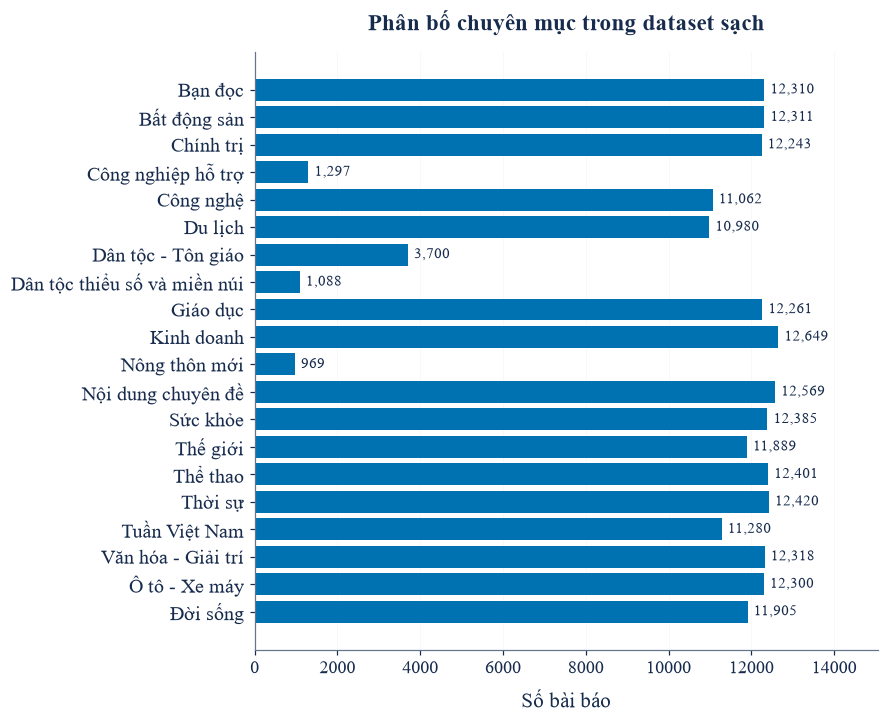

# Phân bố đầu vào: lớp lớn nhất 12,649 bài; lớp nhỏ nhất 969 bài; tỷ lệ 13.05 lần.


In [10]:
raw_classes = sorted(CATEGORY_LABELS.values())
raw_counts = df_raw.label.value_counts().reindex(raw_classes, fill_value=0)
horizontal_plot(raw_counts.to_numpy(), raw_classes,
                'Phân bố chuyên mục trong dataset sạch', 'Số bài báo',
                'dataset/raw_class_distribution')
log(f'Phân bố đầu vào: lớp lớn nhất {raw_counts.max():,} bài; '
    f'lớp nhỏ nhất {raw_counts.min():,} bài; tỷ lệ {raw_counts.max() / raw_counts.min():.2f} lần.')


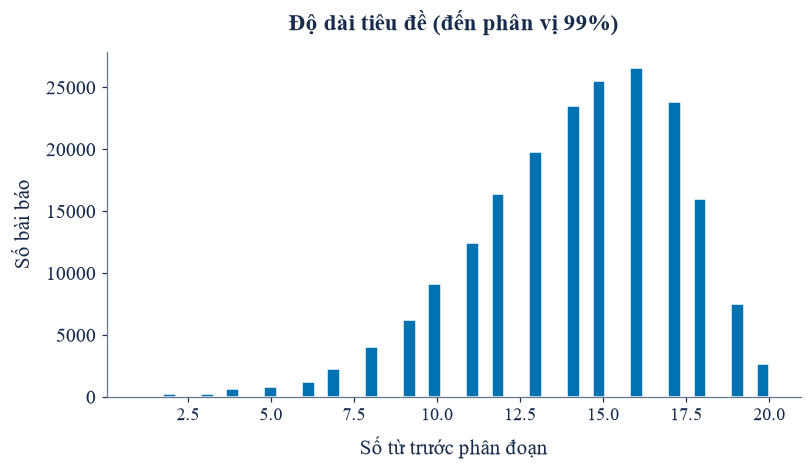

In [11]:
raw_lengths = df_raw['title'].map(lambda text: len(text.split())).to_numpy()
cap = np.quantile(raw_lengths, 0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(raw_lengths[raw_lengths <= cap], bins=50,
        color=COLORS['primary'], edgecolor='white')
ax.set(xlabel='Số từ trước phân đoạn', ylabel='Số bài báo',
       title='Độ dài tiêu đề (đến phân vị 99%)')
save_fig(fig, 'dataset/raw_title_words_length')


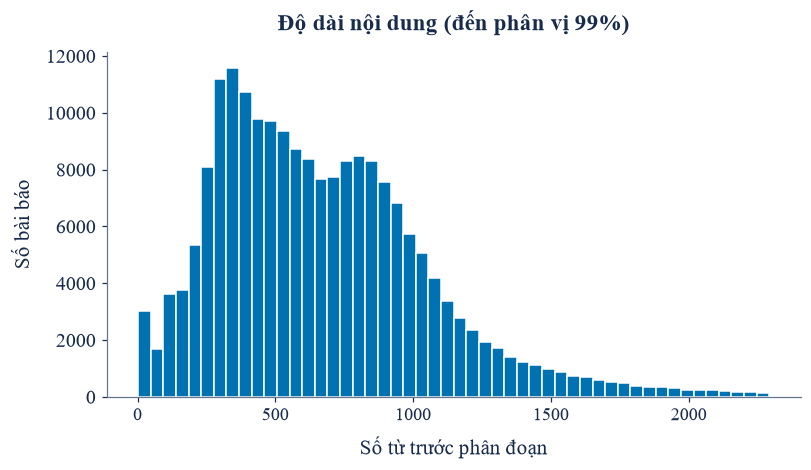

In [12]:
raw_lengths = df_raw['content'].map(lambda text: len(text.split())).to_numpy()
cap = np.quantile(raw_lengths, 0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(raw_lengths[raw_lengths <= cap], bins=50,
        color=COLORS['primary'], edgecolor='white')
ax.set(xlabel='Số từ trước phân đoạn', ylabel='Số bài báo',
       title='Độ dài nội dung (đến phân vị 99%)')
save_fig(fig, 'dataset/raw_content_words_length')


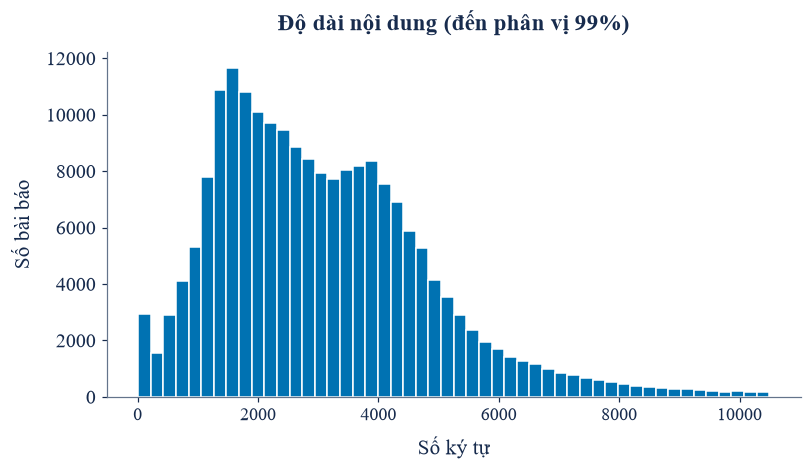

In [13]:
raw_lengths = df_raw['content'].map(len).to_numpy()
cap = np.quantile(raw_lengths, 0.99)
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.hist(raw_lengths[raw_lengths <= cap], bins=50,
        color=COLORS['primary'], edgecolor='white')
ax.set(xlabel='Số ký tự', ylabel='Số bài báo',
       title='Độ dài nội dung (đến phân vị 99%)')
save_fig(fig, 'dataset/raw_content_characters_length')


In [14]:
raw_statistics = []
for label in raw_classes:
    lengths_for_class = df_raw.loc[df_raw.label == label, 'content'].map(lambda text: len(text.split()))
    raw_statistics.append({
        'Nhãn': label, 'Số bài': len(lengths_for_class),
        'Tỷ lệ (%)': 100 * len(lengths_for_class) / len(df_raw),
        'Trung bình số từ': lengths_for_class.mean(),
        'Trung vị số từ': lengths_for_class.median(),
        'Phân vị 95%': lengths_for_class.quantile(0.95),
    })
raw_statistics = pd.DataFrame(raw_statistics)
raw_statistics.to_csv(EVALUATION_DIR / 'raw_dataset_statistics.csv', index=False, encoding='utf-8-sig')
display(raw_statistics.round(2))


,Nhãn,Số bài,Tỷ lệ (%),Trung bình số từ,Trung vị số từ,Phân vị 95%
0,Bạn đọc,12310,6.14,677.25,662.0,1179.00
1,Bất động sản,12311,6.15,740.08,765.0,1175.00
2,Chính trị,12243,6.11,936.46,813.0,2042.90
3,Công nghiệp hỗ trợ,1297,0.65,786.84,711.0,1528.20
4,Công nghệ,11062,5.52,789.20,772.0,1358.95
5,Du lịch,10980,5.48,597.20,537.0,1261.05
6,Dân tộc - Tôn giáo,3700,1.85,928.91,833.0,1862.30
7,Dân tộc thiểu số và miền núi,1088,0.54,578.74,543.0,1150.15
8,Giáo dục,12261,6.12,644.00,594.0,1215.00
9,Kinh doanh,12649,6.31,787.99,782.0,1311.00


## Tiền xử lý văn bản

Ghép tiêu đề và nội dung, chuyển chữ thường, thay dấu câu và chữ số,
phân đoạn bằng PyVi rồi chuẩn hóa khoảng trắng. Stopwords được giữ ở bước chuẩn hóa corpus; chỉ loại khi tạo đầu vào TF-IDF.
Mỗi tiến trình xử lý có tokenizer riêng; dữ liệu đã xử lý được lưu để tái sử dụng.

Loại văn bản rỗng sau chuẩn hóa. Với văn bản giống nhau nhưng khác nhãn, loại toàn bộ
nhóm xung đột; với văn bản trùng cùng nhãn, giữ một bài. Thực hiện trước khi chia tập
để cùng một văn bản không xuất hiện ở cả train và test.


In [15]:
started = time.perf_counter()
cache_path = TEMP_DIR / 'canonical_text.parquet'
cache_signature_path = TEMP_DIR / 'canonical_signature.json'
cache_valid = (cache_path.is_file() and cache_signature_path.is_file() and
               json.loads(cache_signature_path.read_text(encoding='utf-8')).get('signature')
               == source_signature)
if cache_valid:
    canonical = pd.read_parquet(cache_path)
    if len(canonical) != len(df_raw) or not np.array_equal(
        canonical.article_index.to_numpy(), np.arange(len(df_raw))
    ):
        raise RuntimeError('Cache văn bản không khớp corpus đầu vào.')
    log('Nạp cache văn bản có fingerprint phù hợp.')
else:
    canonical = pd.DataFrame({'article_index': np.arange(len(df_raw))})
    canonical['clean_text'] = segment_parallel(
        (df_raw.title + ' ' + df_raw.content).tolist(), 'Phân đoạn từ tiếng Việt')
    canonical.to_parquet(cache_path, index=False)
    write_json(cache_signature_path, {'signature': source_signature})
df = canonical.assign(label=df_raw.label.to_numpy())
df = df.loc[df.clean_text.str.strip() != ''].copy()
ambiguous = df.groupby('clean_text')['label'].transform('nunique') > 1
conflicting_count = int(ambiguous.sum())
df = df.loc[~ambiguous]
before_dedup = len(df)
df = df.drop_duplicates('clean_text').reset_index(drop=True)
duplicate_count = before_dedup - len(df)
df_raw = df_raw.iloc[df.article_index.to_numpy()].reset_index(drop=True)
classes = sorted(CATEGORY_LABELS.values())
label2id = {label: index for index, label in enumerate(classes)}
N_CLASSES = len(classes)
if set(df.label) != set(classes) or df.label.value_counts().min() < 7:
    raise RuntimeError('Mỗi lớp cần ít nhất bảy văn bản chuẩn hóa khác nhau.')
labels = df.label.map(label2id).to_numpy(dtype=np.int64)
corpus_signature = fingerprint({
    'source': source_signature, 'article_indices': df.article_index.tolist(),
    'clean_hashes': pd.util.hash_pandas_object(df.clean_text, index=False).tolist(),
})
preprocessing_seconds = time.perf_counter() - started
del canonical
write_json(EVALUATION_DIR / 'dataset_audit.json', {
    'source_count': sum(dataset_audit['after'].values()), 'corpus_count': len(df),
    'conflicting_label_rows_removed': conflicting_count,
    'same_label_duplicate_rows_removed': duplicate_count,
    'class_counts': {label: int((df.label == label).sum()) for label in classes},
    'source_signature': source_signature, 'corpus_signature': corpus_signature,
})
log(f'Corpus: {len(df):,} bài; loại {conflicting_count:,} bài xung đột nhãn và '
    f'{duplicate_count:,} bản trùng cùng nhãn.')


# Phân đoạn từ tiếng Việt: [########################] 200,337/200,337 (100.0%) | 661 giây | 303.1 mục/giây

# Corpus: 199,965 bài; loại 8 bài xung đột nhãn và 364 bản trùng cùng nhãn.


In [16]:
example = df_raw.iloc[0]
source_text = (example.title + ' ' + example.content).strip()
display(pd.DataFrame([
    {'Giai đoạn': 'Văn bản đầu vào', 'Trích đoạn': source_text[:500]},
    {'Giai đoạn': 'Chữ thường, dấu câu và chữ số', 'Trích đoạn': prepare_text(source_text)[:500]},
    {'Giai đoạn': 'Phân đoạn từ và chuẩn hóa khoảng trắng', 'Trích đoạn': segmented_text(source_text)[:500]},
]))


,Giai đoạn,Trích đoạn
0,Văn bản đầu vào,"1 triệu trang phục UNIQLO tặng trẻ em, nạn nhâ..."
1,"Chữ thường, dấu câu và chữ số",triệu trang phục uniqlo tặng trẻ em nạn nhâ...
2,Phân đoạn từ và chuẩn hóa khoảng trắng,triệu trang_phục uniqlo tặng trẻ_em nạn_nhân t...


---
## Chia train, validation và test

Chia phân tầng 70/15/15 sau khi loại văn bản trùng; ba tập không giao nhau theo URL,
văn bản gốc hoặc văn bản sạch. Mỗi tập có đủ 20 nhãn. Vocabulary và các tham số
biểu diễn chỉ được học từ train; validation/test giữ phân bố tự nhiên.


In [17]:
train_indices, holdout_indices = train_test_split(
    np.arange(len(df)), test_size=VAL_SIZE + TEST_SIZE,
    random_state=RANDOM_STATE, stratify=df.label)
val_indices, test_indices = train_test_split(
    holdout_indices, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    random_state=RANDOM_STATE, stratify=df.label.iloc[holdout_indices])
split_indices = {'train': train_indices, 'validation': val_indices, 'test': test_indices}
split_names = {'train': 'Huấn luyện', 'validation': 'Validation', 'test': 'Test'}
raw_hashes = pd.util.hash_pandas_object(df_raw.title + ' ' + df_raw.content, index=False).to_numpy()
leakage_rows = []
assert np.array_equal(np.sort(np.concatenate(list(split_indices.values()))), np.arange(len(df)))
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    for name, keys in [('URL', df_raw.url), ('Văn bản gốc', raw_hashes),
                       ('Văn bản chuẩn hóa', df.clean_text)]:
        first = np.asarray(keys)[split_indices[left]]
        second = np.asarray(keys)[split_indices[right]]
        overlap = len(set(first) & set(second))
        leakage_rows.append({'left': left, 'right': right, 'key': name, 'overlap': overlap})
        if overlap:
            raise RuntimeError('Rò rỉ dữ liệu giữa các tập; kiểm tra corpus trước khi huấn luyện.')
for name, indices in split_indices.items():
    assert set(labels[indices]) == set(range(N_CLASSES)), f'Tập {name} thiếu nhãn.'
y_train, y_val, y_test = [labels[indices] for indices in split_indices.values()]
train_class_counts = np.bincount(y_train, minlength=N_CLASSES)
split_signature = fingerprint({'corpus': corpus_signature,
                               'indices': {name: indices.tolist() for name, indices in split_indices.items()}})
split_manifest = {
    'seed': RANDOM_STATE,
    'requested_ratios': {'train': TRAIN_SIZE, 'validation': VAL_SIZE, 'test': TEST_SIZE},
    'counts': {name: len(indices) for name, indices in split_indices.items()},
    'indices': {name: indices.tolist() for name, indices in split_indices.items()},
    'urls_sha256': {name: fingerprint(df_raw.url.iloc[indices].tolist())
                    for name, indices in split_indices.items()},
    'corpus_signature': corpus_signature, 'split_signature': split_signature,
    'deduplication': 'clean_text; conflicting labels removed; identical texts kept once',
    'selection_split': 'validation', 'calibration_fit_split': 'validation',
    'evaluation_split': 'test', 'pairwise_disjoint': True,
}
write_json(EVALUATION_DIR / 'split_manifest.json', split_manifest)
write_json(EVALUATION_DIR / 'leakage_audit.json', leakage_rows)
write_json(MODEL_DIR / 'labels.json', {'classes': classes, 'label2id': label2id})
log(f'Train {len(y_train):,} | Validation {len(y_val):,} | Test {len(y_test):,}.')
log(f'Tỷ lệ lớp nhiều nhất/ít nhất trong train: '
    f'{train_class_counts.max() / train_class_counts.min():.2f} lần.')
display(pd.DataFrame({'ID': np.arange(N_CLASSES), 'Nhãn': classes,
                      'Train': train_class_counts,
                      'Validation': np.bincount(y_val, minlength=N_CLASSES),
                      'Test': np.bincount(y_test, minlength=N_CLASSES)}))


# Train 139,975 | Validation 29,995 | Test 29,995.
# Tỷ lệ lớp nhiều nhất/ít nhất trong train: 13.05 lần.


,ID,Nhãn,Train,Validation,Test
0,0,Bạn đọc,8483,1818,1818
1,1,Bất động sản,8616,1847,1846
2,2,Chính trị,8569,1837,1836
3,3,Công nghiệp hỗ trợ,905,193,194
4,4,Công nghệ,7743,1659,1659
5,5,Du lịch,7685,1647,1647
6,6,Dân tộc - Tôn giáo,2590,555,555
7,7,Dân tộc thiểu số và miền núi,762,163,163
8,8,Giáo dục,8581,1839,1839
9,9,Kinh doanh,8850,1896,1897


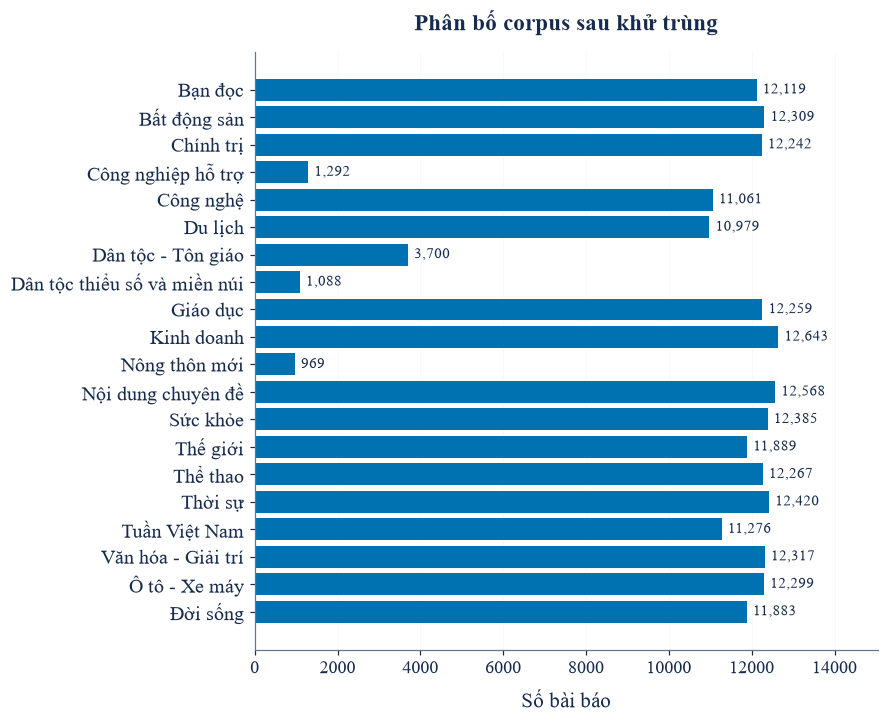

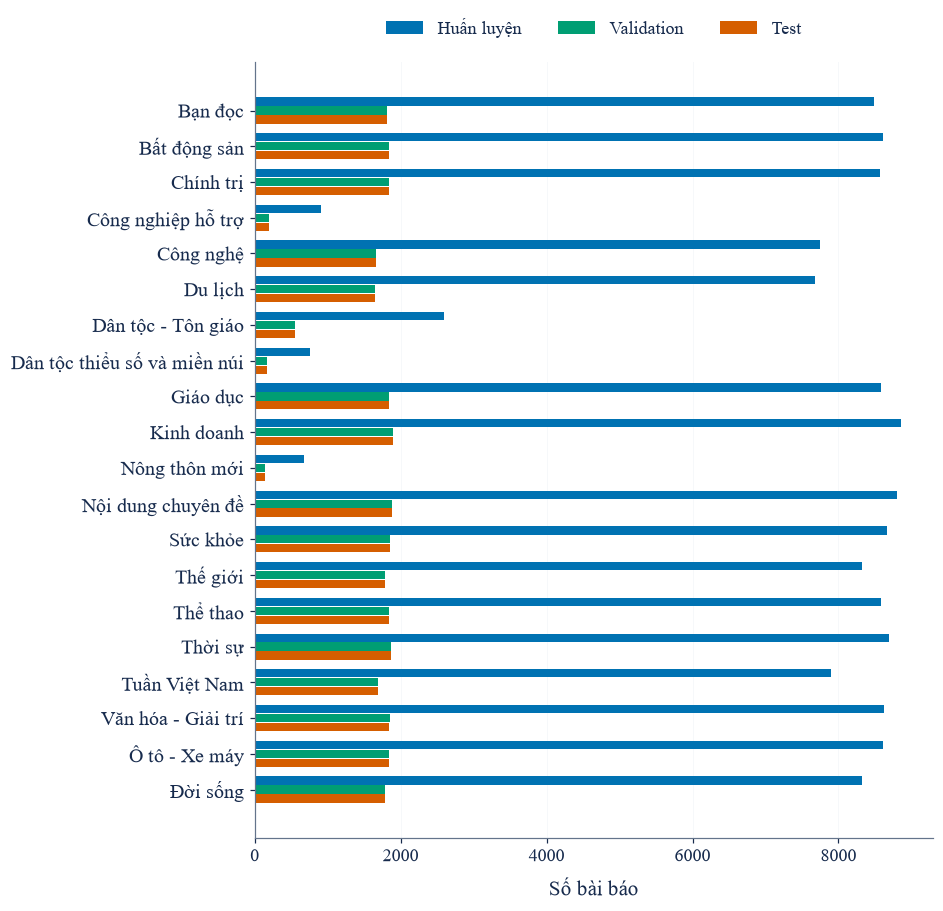

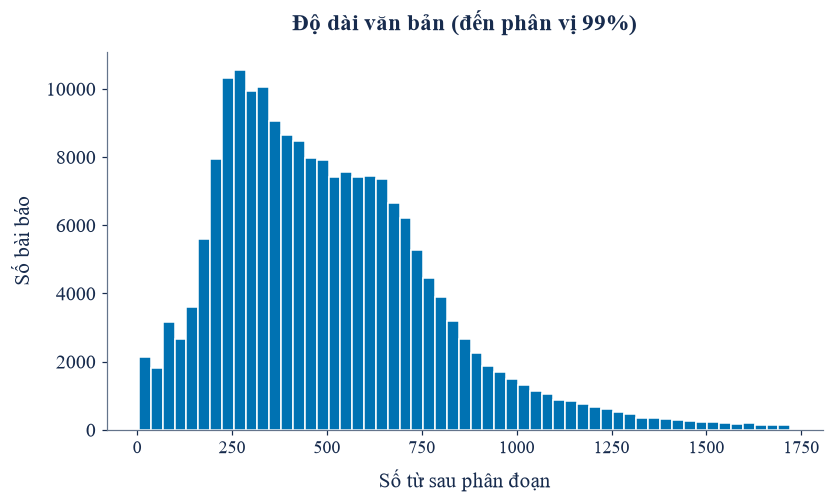

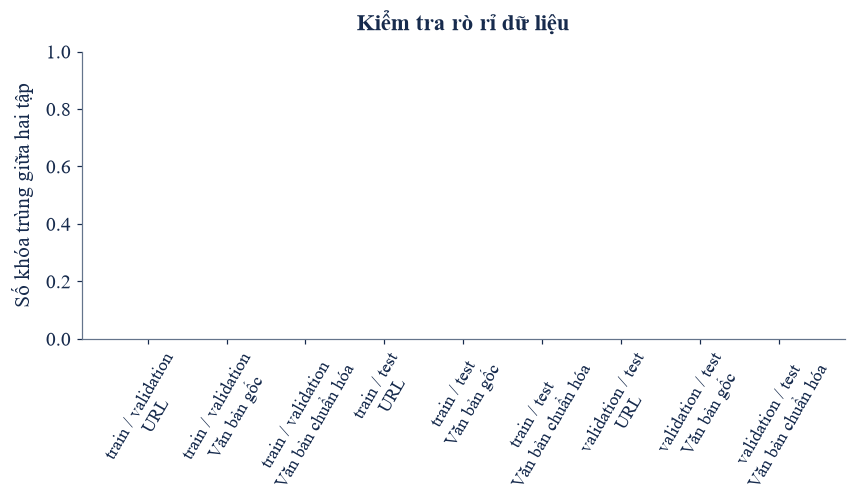

In [18]:
horizontal_plot(np.bincount(labels, minlength=N_CLASSES), classes,
                'Phân bố corpus sau khử trùng', 'Số bài báo', 'dataset/class_distribution')
fig, ax = plt.subplots(figsize=(8.8, 8.5))
positions = np.arange(N_CLASSES)
for offset, name, color in [(-0.25, 'train', 'primary'), (0, 'validation', 'secondary'),
                            (0.25, 'test', 'warning')]:
    ax.barh(positions + offset, np.bincount(labels[split_indices[name]], minlength=N_CLASSES),
            height=0.23, label=split_names[name], color=COLORS[color])
ax.set(yticks=positions, yticklabels=classes, xlabel='Số bài báo')
ax.invert_yaxis()
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=False)
ax.grid(axis='x', alpha=0.18)
save_fig(fig, 'dataset/split_distribution')
lengths = df.clean_text.map(lambda text: len(text.split())).to_numpy()
fig, ax = plt.subplots(figsize=(7.8, 4.8))
cap = np.quantile(lengths, 0.99)
ax.hist(lengths[lengths <= cap], bins=55, color=COLORS['primary'], edgecolor='white')
ax.set(xlabel='Số từ sau phân đoạn', ylabel='Số bài báo',
       title='Độ dài văn bản (đến phân vị 99%)')
save_fig(fig, 'dataset/text_length')
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(np.arange(len(leakage_rows)), [row['overlap'] for row in leakage_rows], color=COLORS['primary'])
ax.set(xticks=np.arange(len(leakage_rows)),
       xticklabels=[f"{row['left']} / {row['right']}\n{row['key']}" for row in leakage_rows],
       ylabel='Số khóa trùng giữa hai tập', ylim=(0, 1), title='Kiểm tra rò rỉ dữ liệu')
ax.tick_params(axis='x', labelrotation=60)
save_fig(fig, 'dataset/split_overlap')


## Biểu diễn TF-IDF

Tiêu đề có trọng số 3: ghép tiêu đề hai lần thêm vào văn bản đã có tiêu đề và nội dung.
Stopword được chuẩn hóa theo cách phân đoạn tiếng Việt, giữ dấu gạch dưới trong từ ghép.
Chỉ tạo biểu diễn riêng sau khi chia tập; việc tăng trọng số tiêu đề hoặc loại stopwords
không thay đổi các mẫu train, validation và test đã xác định.

TF-IDF dùng tần suất logarit, chuẩn hóa L2 và từ đơn hoặc từ đơn kết hợp bigram.
Vocabulary cùng IDF chỉ fit trên train; validation/test được transform bằng cùng vectorizer.
Văn bản không còn token sau loại stopwords được biểu diễn bằng token dự phòng.


In [19]:
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.exceptions import ConvergenceWarning
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

STOPWORDS_PATH = RUN_ROOT / 'resources' / MODEL_KEY / 'vietnamese-stopwords.txt'
if not STOPWORDS_PATH.is_file():
    raise FileNotFoundError('Thiếu danh sách stopword riêng của notebook.')
STOPWORDS = frozenset(line.strip().lower().replace(' ', '_')
                      for line in STOPWORDS_PATH.read_text(encoding='utf-8-sig').splitlines()
                      if line.strip())
if not STOPWORDS:
    raise RuntimeError('Danh sách stopword rỗng.')
stopwords_signature = file_sha256(STOPWORDS_PATH)
log(f'Stopword tiếng Việt: {len(STOPWORDS):,} mục; huấn luyện TF-IDF trên CPU.')

def make_model_text(title, content, title_weight=TITLE_WEIGHT):
    title_tokens = segmented_text(title)
    canonical = segmented_text(str(title).strip() + ' ' + str(content).strip())
    tokens = ((title_tokens + ' ') * (title_weight - 1) + canonical).split()
    return ' '.join(token for token in tokens if token not in STOPWORDS) or 'vnn_empty_text'

def fit_with_progress(estimator, matrix, targets, description):
    def task():
        with threadpool_limits(limits=CPU_THREADS), warnings.catch_warnings(record=True) as captured:
            warnings.simplefilter('always', ConvergenceWarning)
            estimator.fit(matrix, targets)
        convergence_messages = [str(item.message) for item in captured
                                 if issubclass(item.category, ConvergenceWarning)]
        other_messages = [str(item.message) for item in captured
                           if not issubclass(item.category, ConvergenceWarning)]
        return estimator, convergence_messages, other_messages
    started = time.perf_counter()
    with ThreadPoolExecutor(max_workers=1) as executor, TextProgress(total=1, desc=description) as progress:
        future = executor.submit(task)
        while not future.done():
            progress.update(0, details='Đang tối ưu trên CPU')
            time.sleep(0.25)
        estimator, convergence_messages, other_messages = future.result()
        progress.update(1, force=True)
    return estimator, time.perf_counter() - started, convergence_messages, other_messages

def new_estimator(config, max_iter):
    common = {'C': config['C'], 'class_weight': config['class_weight'],
              'tol': TOLERANCE, 'max_iter': max_iter, 'random_state': RANDOM_STATE}
    return ESTIMATOR_FACTORY(common)

def predict_scores(vectorizer, estimator, texts, description):
    chunks = []
    with threadpool_limits(limits=CPU_THREADS), TextProgress(total=len(texts), desc=description) as progress:
        for start in range(0, len(texts), 1024):
            batch = texts[start:start + 1024]
            matrix = vectorizer.transform(batch)
            scores = np.asarray(estimator.decision_function(matrix), dtype=np.float64)
            if scores.shape != (len(batch), N_CLASSES) or not np.isfinite(scores).all():
                raise RuntimeError('Điểm dự đoán không hợp lệ.')
            chunks.append(scores)
            progress.update(len(batch))
    return np.concatenate(chunks)

SOLVER_NAME = 'liblinear_dual_auto'
def ESTIMATOR_FACTORY(common):
    return LinearSVC(dual='auto', loss='squared_hinge', **common)


# Stopword tiếng Việt: 1,959 mục; huấn luyện TF-IDF trên CPU.


In [20]:
feature_cache = TEMP_DIR / 'feature_text.parquet'
feature_cache_meta = TEMP_DIR / 'feature_signature.json'
feature_signature = fingerprint({'corpus': corpus_signature, 'stopwords': stopwords_signature,
                                 'title_weight': TITLE_WEIGHT})
if (feature_cache.is_file() and feature_cache_meta.is_file() and
    json.loads(feature_cache_meta.read_text(encoding='utf-8')).get('signature') == feature_signature):
    feature_text = pd.read_parquet(feature_cache).text.tolist()
    if len(feature_text) != len(df):
        raise RuntimeError('Cache đặc trưng sai số lượng bài.')
else:
    title_text = segment_parallel(df_raw.title.tolist(), 'Phân đoạn tiêu đề')
    feature_text = [
        ' '.join(token for token in ((title + ' ') * (TITLE_WEIGHT - 1) + canonical).split()
                 if token not in STOPWORDS) or 'vnn_empty_text'
        for title, canonical in zip(title_text, df.clean_text)
    ]
    pd.DataFrame({'text': feature_text}).to_parquet(feature_cache, index=False)
    write_json(feature_cache_meta, {'signature': feature_signature})
    del title_text
training_texts = [feature_text[i] for i in train_indices]
validation_texts = [feature_text[i] for i in val_indices]
run_signature = fingerprint({
    'split': split_signature, 'features': feature_signature, 'model': MODEL_KEY,
    'sklearn': importlib.metadata.version('scikit-learn'),
})
pipeline_path = MODEL_DIR / 'pipeline.joblib'


# Phân đoạn tiêu đề: [########################] 199,965/199,965 (100.0%) | 18 giây | 10861.2 mục/giây

## Huấn luyện mô hình

SVM tuyến tính dùng squared hinge loss, L2 và one-vs-rest trên vector TF-IDF thưa.

| Thiết lập | Giá trị |
|---|---|
| Biểu diễn | TF-IDF unigram hoặc unigram–bigram |
| Số đặc trưng tối đa | 150.000 |
| Ngưỡng xuất hiện tối thiểu / tối đa | 3 bài / 98% train |
| TF / chuẩn hóa | Logarit / L2 |
| Trọng số tiêu đề | 3 |
| Regularization C | 0,5; 1,5; 3,0 |
| Trọng số lớp | Đồng đều hoặc balanced |
| Solver | LIBLINEAR; tự chọn primal/dual theo kích thước dữ liệu |
| Giới hạn vòng tối ưu | 5.000; tối ưu lại với 20.000 nếu chưa hội tụ |
| Ngưỡng hội tụ | 0,0001 |
| Luồng CPU tối đa | 4 |
| Cấu hình dùng đánh giá | Macro-F1 validation tốt nhất trong các cấu hình hội tụ |

Khảo sát 12 tổ hợp tham số. Mỗi vectorizer fit trên train, sau đó tái sử dụng cho
các giá trị C và trọng số lớp cùng profile. Balanced weight là `N_train / (20 × n_class)`;
số lượng được tính lại sau tiền xử lý, loại trùng và chia tập.

Validation chọn cấu hình theo Macro-F1, rồi Weighted-F1 và Accuracy khi bằng nhau.
Cấu hình chưa hội tụ được tối ưu từ đầu với giới hạn vòng lớn hơn; nếu vẫn chưa hội tụ
thì không tham gia lựa chọn. Test không tham gia tìm tham số. Pipeline được chọn giữ
nguyên train; validation không được đưa thêm vào dữ liệu fit cuối.

Chế độ `fresh` huấn luyện từ đầu. Chế độ `evaluate` nạp pipeline khi dữ liệu, tiền xử lý,
mapping, stopwords và cả ba tập khớp fingerprint.


In [21]:
search_started = time.perf_counter()
search_records = []
selected_config = None
best_estimator = best_vectorizer = None
best_rank = (-1.0, -1.0, -1.0)
selected_fit_seconds = 0.0
if TRAINING_MODE == 'evaluate':
    if not pipeline_path.is_file():
        raise FileNotFoundError('Chưa có model; chọn fresh để huấn luyện.')
    pipeline = joblib.load(pipeline_path)
    if (pipeline['run_signature'] != run_signature or pipeline['classes'] != classes or
        pipeline['stopwords'] != sorted(STOPWORDS)):
        raise RuntimeError('Model không khớp corpus, split hoặc tiền xử lý hiện tại; chọn fresh.')
    best_estimator, best_vectorizer = pipeline['estimator'], pipeline['vectorizer']
    selected_config = pipeline['selected_config']
    timing = pipeline['timing']
else:
    candidate_count = len(TFIDF_PROFILES) * len(REGULARIZATION_C) * len(CLASS_WEIGHT_OPTIONS)
    candidate_id = 0
    for profile in TFIDF_PROFILES:
        log('Tạo TF-IDF: ' + profile['name'].replace('_', ' ') + '; chỉ fit trên train.')
        vectorizer = TfidfVectorizer(
            tokenizer=str.split, token_pattern=None, lowercase=False,
            max_features=profile['max_features'], ngram_range=tuple(profile['ngram_range']),
            min_df=profile['min_df'], max_df=0.98, sublinear_tf=True, norm='l2', dtype=np.float64)
        with threadpool_limits(limits=CPU_THREADS):
            train_matrix = vectorizer.fit_transform(training_texts)
            validation_matrix = vectorizer.transform(validation_texts)
        for c_value in REGULARIZATION_C:
            for weighting in CLASS_WEIGHT_OPTIONS:
                candidate_id += 1
                config = {**profile, 'C': c_value, 'class_weight': weighting,
                           'title_weight': TITLE_WEIGHT, 'stopwords_sha256': stopwords_signature,
                           'max_df': 0.98, 'sublinear_tf': True, 'norm': 'l2',
                           'solver': SOLVER_NAME, 'tol': TOLERANCE}
                estimator = new_estimator(config, MAX_ITERATIONS)
                description = f'Cấu hình {candidate_id}/{candidate_count}'
                estimator, fit_seconds, convergence_messages, other_messages = fit_with_progress(
                    estimator, train_matrix, y_train, description)
                if convergence_messages:
                    log(f'Cấu hình {candidate_id}: tăng giới hạn vòng tối ưu để đạt hội tụ.')
                    estimator = new_estimator(config, RETRY_MAX_ITERATIONS)
                    estimator, extra_seconds, convergence_messages, extra_messages = fit_with_progress(
                        estimator, train_matrix, y_train, description + ' — tối ưu mở rộng')
                    fit_seconds += extra_seconds
                    other_messages.extend(extra_messages)
                with threadpool_limits(limits=CPU_THREADS):
                    predicted = estimator.predict(validation_matrix)
                values = metrics(y_val, predicted)
                iterations = int(np.max(np.atleast_1d(estimator.n_iter_)))
                record = {'candidate': candidate_id, 'config': config, 'validation': values,
                          'fit_seconds': fit_seconds, 'n_iter': iterations,
                          'converged': not convergence_messages,
                          'warnings': convergence_messages + other_messages}
                search_records.append(record)
                write_json(EVALUATION_DIR / 'search_results.json', search_records)
                rank = (values['f1_macro'], values['f1_weighted'], values['accuracy'])
                if not convergence_messages and rank > best_rank:
                    best_rank = rank
                    best_estimator, best_vectorizer = estimator, vectorizer
                    selected_config = {**config, 'n_features': train_matrix.shape[1],
                                       'n_iter': iterations, 'max_iter': estimator.max_iter}
                    selected_fit_seconds = fit_seconds
                log(f'Cấu hình {candidate_id}: Macro-F1 validation {values["f1_macro"]:.4f}; '
                    + ('đã hội tụ.' if not convergence_messages else 'chưa hội tụ; không chọn.'))
        del train_matrix, validation_matrix
    if selected_config is None:
        raise RuntimeError('Chưa có cấu hình hội tụ; tăng giới hạn tối ưu trước khi đánh giá test.')
    timing = {'search_seconds': time.perf_counter() - search_started,
              'selected_fit_seconds': selected_fit_seconds,
              'inference_scope': 'TF-IDF transform + decision_function; excludes Vietnamese segmentation'}
    joblib.dump({
        'estimator': best_estimator, 'vectorizer': best_vectorizer,
        'classes': classes, 'stopwords': sorted(STOPWORDS),
        'selected_config': selected_config, 'run_signature': run_signature,
        'timing': timing,
    }, pipeline_path, compress=3)
write_json(MODEL_DIR / 'selected_config.json', selected_config)
if not np.array_equal(best_estimator.classes_, np.arange(N_CLASSES)):
    raise RuntimeError('Thứ tự đầu ra model không khớp label ID.')
validation_scores = predict_scores(best_vectorizer, best_estimator,
                                    validation_texts, 'Dự đoán validation')
log('Chọn cấu hình bằng Macro-F1 validation; không refit thêm validation vào train.')
display_configuration(selected_config)


# Tạo TF-IDF: unigram; chỉ fit trên train.


# Cấu hình 1/12: [########################] 1/1 (100.0%) | 67 giây | 0.0 mục/giây | Đang tối ưu trên CPU

# Cấu hình 1: Macro-F1 validation 0.8286; đã hội tụ.


# Cấu hình 2/12: [########################] 1/1 (100.0%) | 73 giây | 0.0 mục/giây | Đang tối ưu trên CPU

# Cấu hình 2: Macro-F1 validation 0.8415; đã hội tụ.


...

# Cấu hình 12/12: [########################] 1/1 (100.0%) | 47 giây | 0.0 mục/giây | Đang tối ưu trên CPU

# Cấu hình 12: Macro-F1 validation 0.8481; đã hội tụ.


# Dự đoán validation: [########################] 29,995/29,995 (100.0%) | 12 giây | 2529.2 mục/giây

# Chọn cấu hình bằng Macro-F1 validation; không refit thêm validation vào train.


,Tham số,Giá trị
0,Cấu hình,unigram bigram
1,Số đặc trưng tối đa,150000
2,N-gram,"(1, 2)"
3,Ngưỡng xuất hiện tối thiểu,3
4,Hệ số C,0.5
5,Trọng số lớp,balanced
6,Trọng số tiêu đề,3
7,Tỷ lệ xuất hiện tối đa,0.98
8,TF logarit,True
9,Chuẩn hóa vector,l2


---
## Đánh giá mô hình

Tạo báo cáo phân loại, ma trận nhầm lẫn và chỉ số Accuracy, Macro-F1, Weighted-F1
trên test độc lập. Chỉ cấu hình được chọn bằng validation đi qua bước này.
Temperature được fit trên validation rồi giữ cố định trước khi dự đoán test.
Khoảng tin cậy 95% dùng bootstrap test cho một mô hình cố định, không thay thế
thực nghiệm nhiều seed.


In [22]:
# Temperature chỉ được ước lượng trên validation, không dùng nhãn test.
def validation_nll(log_temperature):
    scaled = np.asarray(validation_scores, dtype=np.float64) / np.exp(log_temperature)
    return float(np.mean(logsumexp(scaled, axis=1) - scaled[np.arange(len(y_val)), y_val]))
fit = minimize_scalar(validation_nll, bounds=(np.log(0.05), np.log(20.0)), method='bounded')
if not fit.success or not np.isfinite(fit.fun):
    raise RuntimeError('Không tìm được temperature hợp lệ từ validation.')
temperature = float(np.exp(fit.x))
if validation_nll(0.0) < fit.fun:
    temperature = 1.0
write_json(MODEL_DIR / 'calibration.json', {
    'temperature': temperature, 'fit_split': 'validation',
    'objective': 'negative_log_likelihood', 'decision': 'argmax_raw_scores',
    'probability_source': SCORE_KIND,
})
log(f'Temperature validation: {temperature:.4f}; tham số đã cố định trước đánh giá test.')


# Temperature validation: 0.2718; tham số đã cố định trước đánh giá test.


In [23]:
started = time.perf_counter()
test_scores = predict_scores(best_vectorizer, best_estimator,
                              [feature_text[i] for i in test_indices], 'Dự đoán test độc lập')
test_inference_seconds = time.perf_counter() - started


# Dự đoán test độc lập: [########################] 29,995/29,995 (100.0%) | 13 giây | 2369.1 mục/giây

In [24]:
test_predictions = np.asarray(test_scores).argmax(axis=1).astype(np.int64)
test_probabilities = temperature_probabilities(test_scores, temperature)
assert np.array_equal(test_predictions, test_probabilities.argmax(axis=1))
test_metrics = metrics(y_test, test_predictions)
before = probability_diagnostics(test_scores, y_test, 1.0)
after = probability_diagnostics(test_scores, y_test, temperature)
report = classification_report(y_test, test_predictions, labels=np.arange(N_CLASSES),
                                target_names=classes, output_dict=True, zero_division=0)
matrix = confusion_matrix(y_test, test_predictions, labels=np.arange(N_CLASSES))
intervals = bootstrap_intervals(y_test, test_predictions)
report_text = classification_report(y_test, test_predictions, labels=np.arange(N_CLASSES),
                                    target_names=classes, digits=4, zero_division=0)
print(report_text)
(RESULT_DIR / 'classification_report.txt').write_text(report_text, encoding='utf-8')
write_json(EVALUATION_DIR / 'classification_report.json', report)
write_json(EVALUATION_DIR / 'confusion_matrix.json', matrix.tolist())
write_json(EVALUATION_DIR / 'confusion_matrix_normalized.json',
           (matrix / np.maximum(matrix.sum(1, keepdims=True), 1)).tolist())
summary = {
    'model': MODEL_NAME, 'model_key': MODEL_KEY, 'selected_config': selected_config,
    'classes': classes, 'selection_split': 'validation', 'evaluation_split': 'test',
    'selection_metric': 'f1_macro', 'validation': metrics(y_val, validation_scores.argmax(axis=1)),
    'before': {**test_metrics, 'nll': before['nll'], 'ece_15_bins': before['ece_15_bins']},
    'after': {**test_metrics, 'nll': after['nll'], 'ece_15_bins': after['ece_15_bins']},
    'temperature': temperature, 'class_decision_adjustment': False,
    'probability_source': SCORE_KIND, 'confidence_intervals_95': intervals,
    'bootstrap': {'resamples': BOOTSTRAP_RESAMPLES, 'method': 'iid_percentile_fixed_model',
                  'seed': RANDOM_STATE},
    'corpus_count': len(df), 'split_counts': split_manifest['counts'],
    'corpus_signature': corpus_signature, 'split_signature': split_signature,
    'test_urls_sha256': split_manifest['urls_sha256']['test'],
    'timing': {**timing, 'preprocessing_seconds': preprocessing_seconds,
               'test_inference_seconds': test_inference_seconds,
               'inference_samples_per_second': len(y_test) / max(test_inference_seconds, 1e-9)},
    'environment': {'python': platform.python_version(), 'platform': platform.platform(),
                    'cpu_threads': CPU_THREADS,
                    'versions': {package: importlib.metadata.version(package)
                                 for package in ENV_PACKAGES}, 'training_device': TRAIN_DEVICE},
}
write_json(EVALUATION_DIR / 'metrics.json', summary)
write_json(EVALUATION_DIR / 'comparison_summary.json', summary)
write_json(EVALUATION_DIR / 'calibration_diagnostics.json', {'before': before, 'after': after})
np.savez_compressed(EVALUATION_DIR / 'test_scores.npz', scores=test_scores, labels=y_test,
                    indices=test_indices)
predictions = pd.DataFrame({
    'url': df_raw.url.iloc[test_indices].to_numpy(), 'corpus_index': test_indices,
    'true_id': y_test, 'predicted_id': test_predictions,
    'true_label': [classes[i] for i in y_test],
    'predicted_label': [classes[i] for i in test_predictions],
    'confidence': test_probabilities[np.arange(len(y_test)), test_predictions],
    'correct': y_test == test_predictions,
})
predictions.to_parquet(EVALUATION_DIR / 'predictions.parquet', index=False)
errors = predictions.loc[~predictions.correct].sort_values('confidence', ascending=False).head(30)
examples = []
for row in errors.to_dict('records'):
    article = df_raw.iloc[int(row['corpus_index'])]
    examples.append({**row, 'title': article.title, 'content_excerpt': article.content[:500]})
write_json(EVALUATION_DIR / 'error_examples.json', examples)
diagnostic_table = pd.DataFrame([
    {'ID': i, 'Nhãn': label, 'Precision': report[label]['precision'],
     'Recall': report[label]['recall'], 'F1': report[label]['f1-score'],
     'Support': int(report[label]['support'])}
    for i, label in enumerate(classes)])
diagnostic_table.to_csv(EVALUATION_DIR / 'per_class_metrics.csv', index=False, encoding='utf-8-sig')
display(diagnostic_table)
log(f'Test {len(y_test):,} bài: Accuracy {test_metrics["accuracy"]:.4f}, '
    f'Macro-F1 {test_metrics["f1_macro"]:.4f}, Weighted-F1 {test_metrics["f1_weighted"]:.4f}.')


                              precision    recall  f1-score   support

                     Bạn đọc     0.9695    0.9439    0.9565      1818
                Bất động sản     0.9049    0.9437    0.9239      1846
                   Chính trị     0.8687    0.8900    0.8792      1836
          Công nghiệp hỗ trợ     0.8605    0.9536    0.9046       194
                   Công nghệ     0.8844    0.8945    0.8894      1659
                     Du lịch     0.8587    0.9004    0.8791      1647
          Dân tộc - Tôn giáo     0.6562    0.6775    0.6667       555
Dân tộc thiểu số và miền núi     0.5167    0.6626    0.5806       163
                    Giáo dục     0.9207    0.9282    0.9245      1839
                  Kinh doanh     0.8571    0.8255    0.8410      1897
               Nông thôn mới     0.4554    0.3493    0.3953       146
          Nội dung chuyên đề     0.7920    0.7411    0.7657      1885
                    Sức khỏe     0.9412    0.9488    0.9450      1857
                   

,ID,Nhãn,Precision,Recall,F1,Support
0,0,Bạn đọc,0.969492,0.943894,0.956522,1818
1,1,Bất động sản,0.904935,0.943662,0.923893,1846
2,2,Chính trị,0.868687,0.889978,0.879204,1836
3,3,Công nghiệp hỗ trợ,0.860465,0.953608,0.904645,194
4,4,Công nghệ,0.884386,0.894515,0.889422,1659
5,5,Du lịch,0.858715,0.900425,0.879075,1647
6,6,Dân tộc - Tôn giáo,0.656195,0.677477,0.666667,555
7,7,Dân tộc thiểu số và miền núi,0.516746,0.662577,0.580645,163
8,8,Giáo dục,0.920712,0.928222,0.924452,1839
9,9,Kinh doanh,0.857143,0.825514,0.841031,1897


# Test 29,995 bài: Accuracy 0.8991, Macro-F1 0.8533, Weighted-F1 0.8988.


---
## Xuất cấu hình mô hình

Lưu mapping nhãn, cấu hình được chọn và temperature trong `model/svm/` để phục vụ suy luận.
Classifier, vectorizer và stopwords được lưu cùng nhau trong pipeline.
Nạp lại gói đã xuất và đối chiếu dự đoán trên validation để kiểm tra tính nhất quán.


In [25]:
write_json(MODEL_DIR / 'inference_config.json', {
    'model': MODEL_NAME, 'model_key': MODEL_KEY, 'classes': classes,
    'label2id': label2id, 'selected_config': selected_config,
    'temperature': temperature, 'probability_source': SCORE_KIND,
    'class_decision_adjustment': False, 'run_signature': run_signature,
    'preprocessing': 'title + content; lowercase; punctuation/digits removed; PyVi; whitespace normalized',
})


In [26]:
# Kiểm tra gói suy luận đã xuất bằng các bài validation, không thay đổi chỉ số test.
reloaded = joblib.load(pipeline_path)
calibration = json.loads((MODEL_DIR / 'calibration.json').read_text(encoding='utf-8'))
def predict_article(title, content):
    text = make_model_text(title, content, reloaded['selected_config']['title_weight'])
    matrix = reloaded['vectorizer'].transform([text])
    scores = reloaded['estimator'].decision_function(matrix)
    probabilities = temperature_probabilities(scores, calibration['temperature'])[0]
    order = np.argsort(-probabilities, kind='stable')[:3]
    return [{'label': classes[i], 'confidence': float(probabilities[i])} for i in order]
sample_indices = val_indices[:3]
for position, index in enumerate(sample_indices):
    article = df_raw.iloc[int(index)]
    text = make_model_text(article.title, article.content)
    assert text == feature_text[int(index)]
    scores = reloaded['estimator'].decision_function(reloaded['vectorizer'].transform([text]))
    np.testing.assert_allclose(scores[0], validation_scores[position], rtol=1e-6, atol=1e-7)
log('Gói model nạp lại cho điểm số nhất quán với pipeline validation.')
display(pd.DataFrame(predict_article(df_raw.iloc[int(val_indices[0])].title,
                                     df_raw.iloc[int(val_indices[0])].content)))


# Gói model nạp lại cho điểm số nhất quán với pipeline validation.


,label,confidence
0,Tuần Việt Nam,0.999942
1,Ô tô - Xe máy,0.000018
2,Dân tộc - Tôn giáo,0.000011


## Đánh giá hiệu chỉnh trên test

Temperature dương được tối ưu **chỉ trên validation**, rồi giữ cố định.
Phần này đo NLL và ECE trên test theo `softmax(scores / temperature)`.
Với SVM, softmax ánh xạ các margin về phân bố điểm số rồi temperature hiệu chỉnh
trên validation. Đây là ánh xạ xác suất từ margin, không phải xác suất sẵn có của LinearSVC.
Temperature không đổi thứ tự điểm số nên Accuracy, Precision, Recall và F1
trước/sau giống nhau. NLL validation được dùng chọn temperature; NLL hoặc ECE test
không được bảo đảm cải thiện. Không điều chỉnh ngưỡng quyết định riêng cho từng class.


In [27]:
display(pd.DataFrame([
    {'Trạng thái': 'Chưa hiệu chỉnh', **test_metrics,
     'NLL': before['nll'], 'ECE (15 bins)': before['ece_15_bins']},
    {'Trạng thái': 'Temperature', **test_metrics,
     'NLL': after['nll'], 'ECE (15 bins)': after['ece_15_bins']},
]).rename(columns={'accuracy': 'Accuracy', 'f1_macro': 'Macro-F1', 'f1_weighted': 'Weighted-F1'}))
log(f'Temperature validation: {temperature:.4f}; '
    'giữ nguyên quyết định argmax trên test.')


,Trạng thái,Accuracy,Macro-F1,Weighted-F1,NLL,ECE (15 bins)
0,Chưa hiệu chỉnh,0.89915,0.853308,0.898771,1.224086,0.545713
1,Temperature,0.89915,0.853308,0.898771,0.354016,0.020738


# Temperature validation: 0.2718; giữ nguyên quyết định argmax trên test.


---
## Chẩn đoán mô hình

Phần này in ra các tín hiệu quan trọng để phân tích lỗi sau huấn luyện và calibration,
gồm lớp có F1 thấp, mức hỗ trợ và các bài dự đoán sai với độ tin cậy cao.
Các biểu đồ tham số và đặc trưng hỗ trợ diễn giải cấu hình được chọn.


In [28]:
display(diagnostic_table.sort_values(['F1', 'Support'], ascending=[True, True]).head(5))
if examples:
    display(pd.DataFrame(examples)[['title', 'true_label', 'predicted_label', 'confidence', 'url']].head(10)
            .rename(columns={'title': 'Tiêu đề', 'true_label': 'Nhãn đúng',
                             'predicted_label': 'Nhãn dự đoán', 'confidence': 'Độ tin cậy', 'url': 'URL'}))
else:
    log('Không có bài dự đoán sai trong tập test.')


,ID,Nhãn,Precision,Recall,F1,Support
10,10,Nông thôn mới,0.455357,0.349315,0.395349,146
7,7,Dân tộc thiểu số và miền núi,0.516746,0.662577,0.580645,163
6,6,Dân tộc - Tôn giáo,0.656195,0.677477,0.666667,555
11,11,Nội dung chuyên đề,0.791950,0.741114,0.765689,1885
19,19,Đời sống,0.869826,0.813236,0.840580,1783


,Tiêu đề,Nhãn đúng,Nhãn dự đoán,Độ tin cậy,URL
0,The Sonata - sống tận hưởng tại ‘tọa độ quốc t...,Kinh doanh,Bất động sản,0.999930,https://vietnamnet.vn/the-sonata-song-tan-huon...
1,Đường lưỡi bò và con chó của GS Carl Thayer,Nội dung chuyên đề,Tuần Việt Nam,0.999882,https://vietnamnet.vn/duong-luoi-bo-va-con-cho...
2,Một phong thái đĩnh đạc,Nội dung chuyên đề,Tuần Việt Nam,0.999828,https://vietnamnet.vn/mot-phong-thai-dinh-dac-...
3,Hơn 7.300m2 ‘đất vàng’ 132 Bến Vân Đồn về tay ...,Kinh doanh,Bất động sản,0.999791,https://vietnamnet.vn/hon-7-300m2-dat-vang-132...
4,"Nhu cầu chip AI tăng mạnh, doanh thu Nvidia lậ...",Công nghiệp hỗ trợ,Công nghệ,0.999749,https://vietnamnet.vn/nhu-cau-ai-tang-manh-doa...
5,"Thời chuyển đổi số, smartphone luôn là đích nh...",Nội dung chuyên đề,Công nghệ,0.999688,https://vietnamnet.vn/thoi-chuyen-doi-so-smart...
6,Google tích hợp AI Gemini vào hệ sinh thái sản...,Giáo dục,Công nghệ,0.999656,https://vietnamnet.vn/google-tich-hop-ai-gemin...
7,Viện dưỡng lão đã không còn đáng sợ,Nội dung chuyên đề,Văn hóa - Giải trí,0.999541,https://vietnamnet.vn/vien-duong-lao-da-khong-...
8,Loạt dự án ôm 'đất vàng' ven biển Đà Nẵng rồi ...,Kinh doanh,Bất động sản,0.999526,https://vietnamnet.vn/can-canh-loat-du-an-om-d...
9,Hà Nội: hạ tầng khu đông tạo đà cho thị trường...,Kinh doanh,Bất động sản,0.999477,https://vietnamnet.vn/ha-noi-ha-tang-khu-dong-...


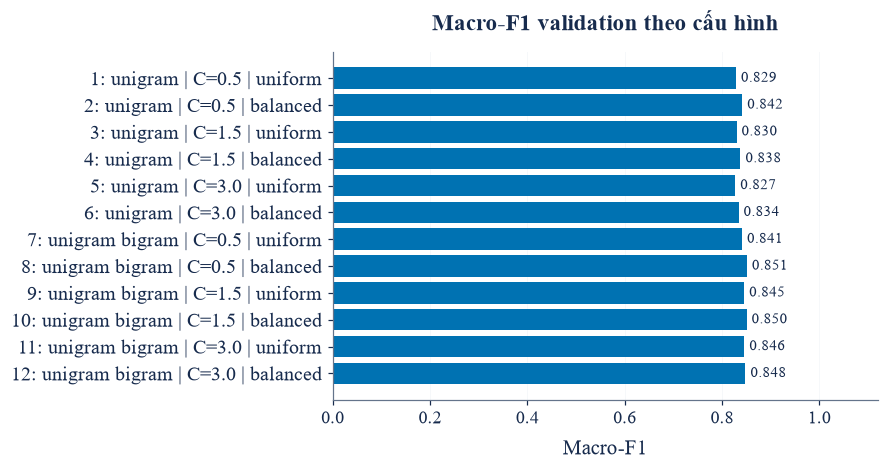

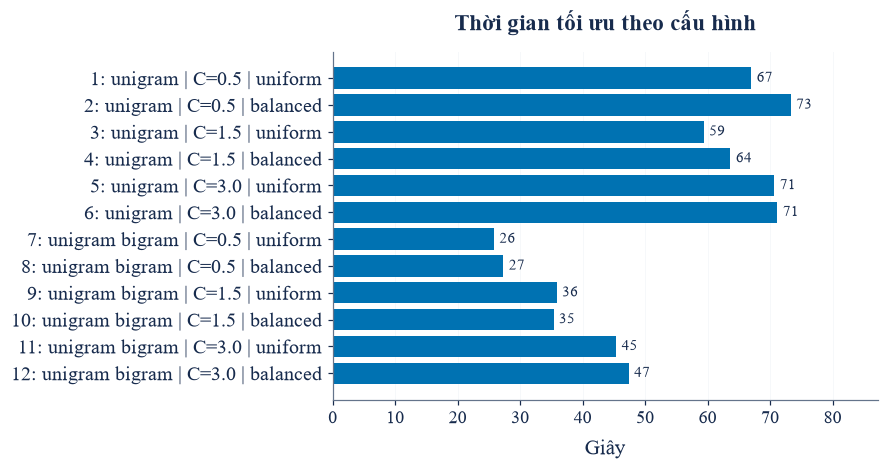

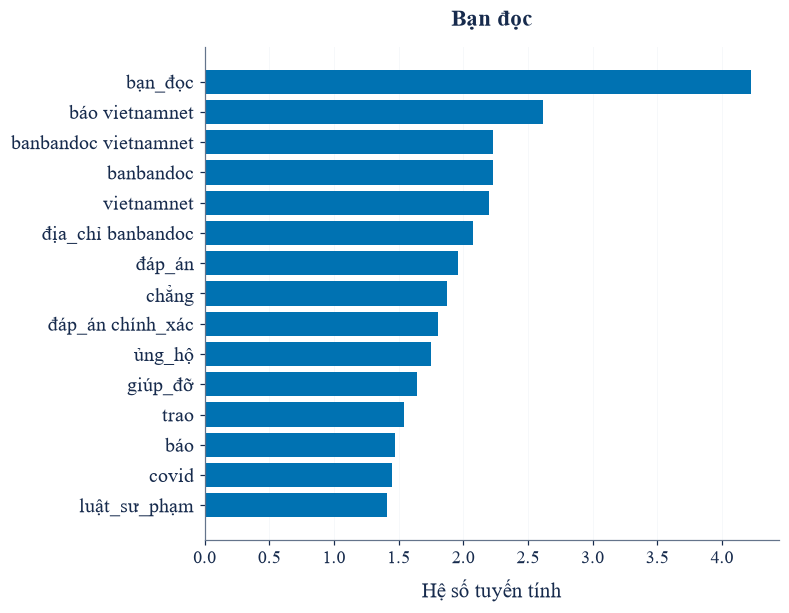

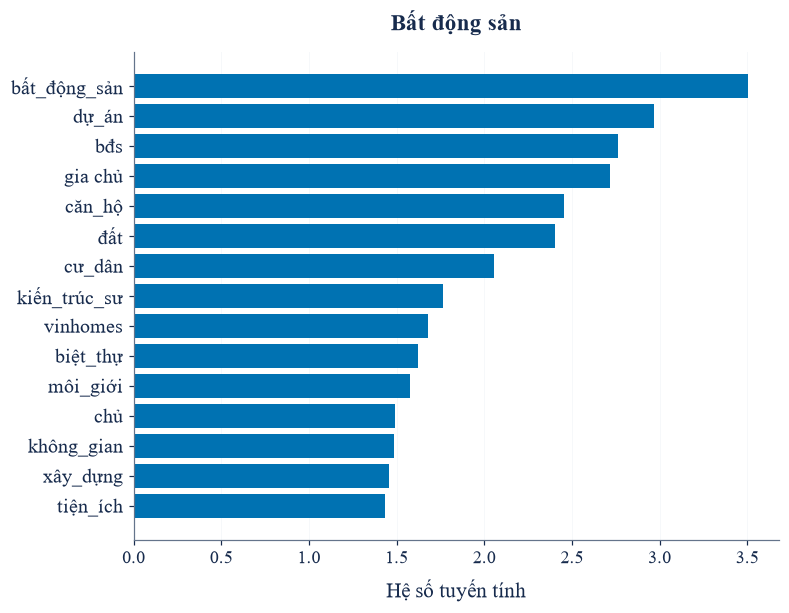

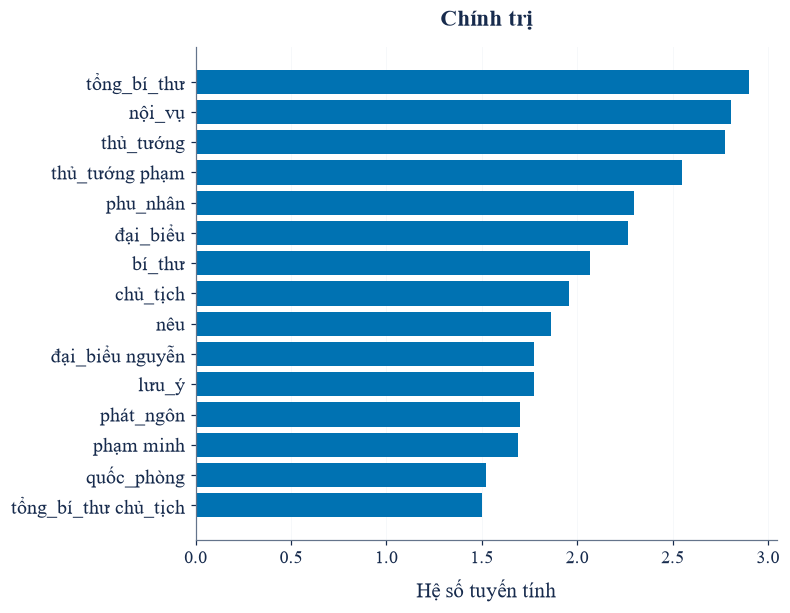

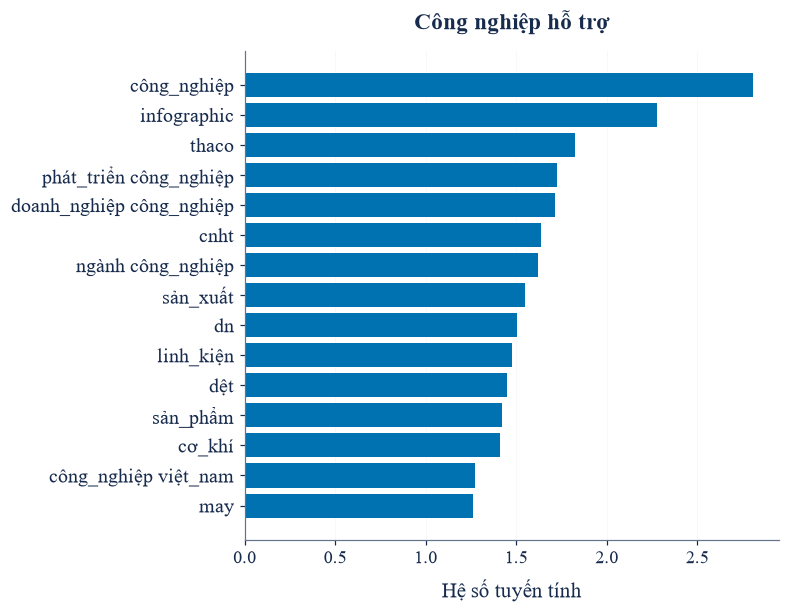

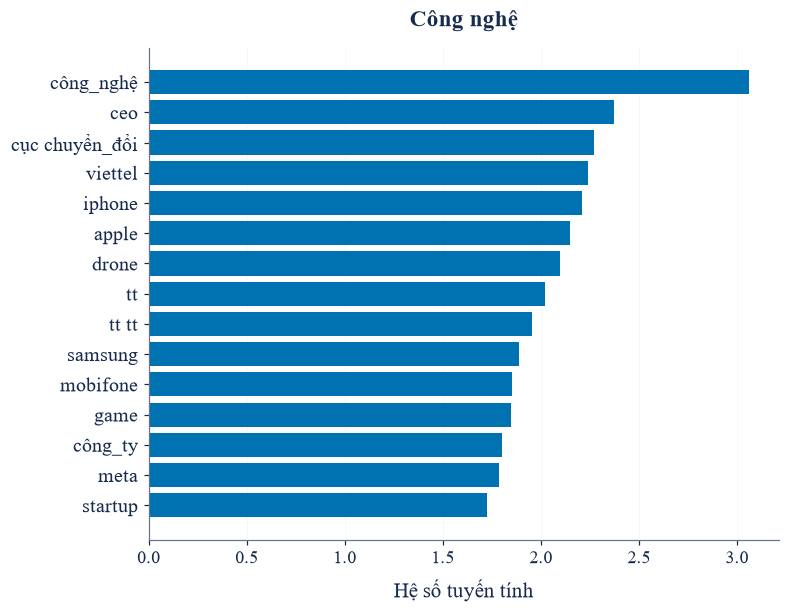

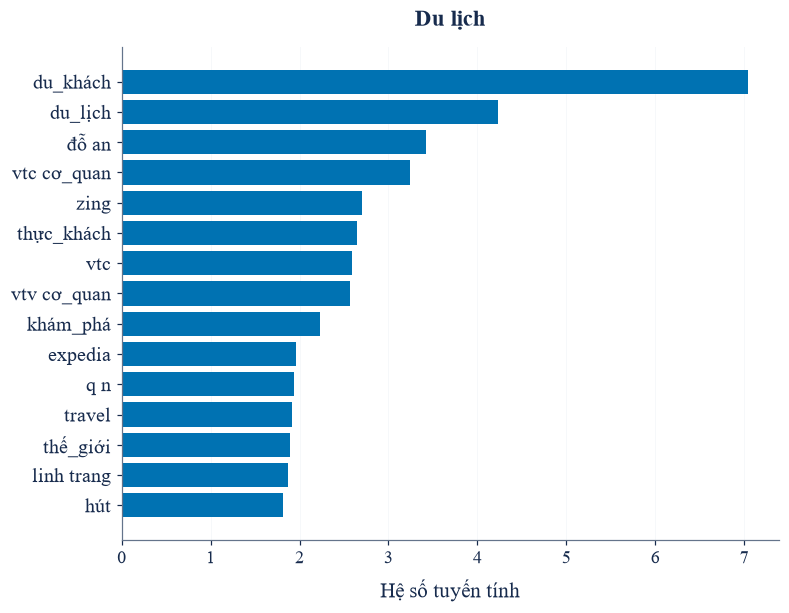

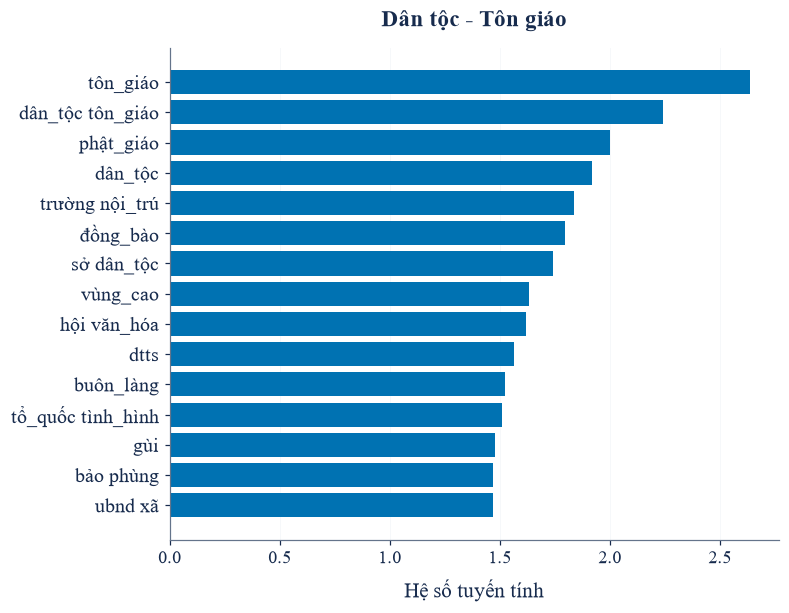

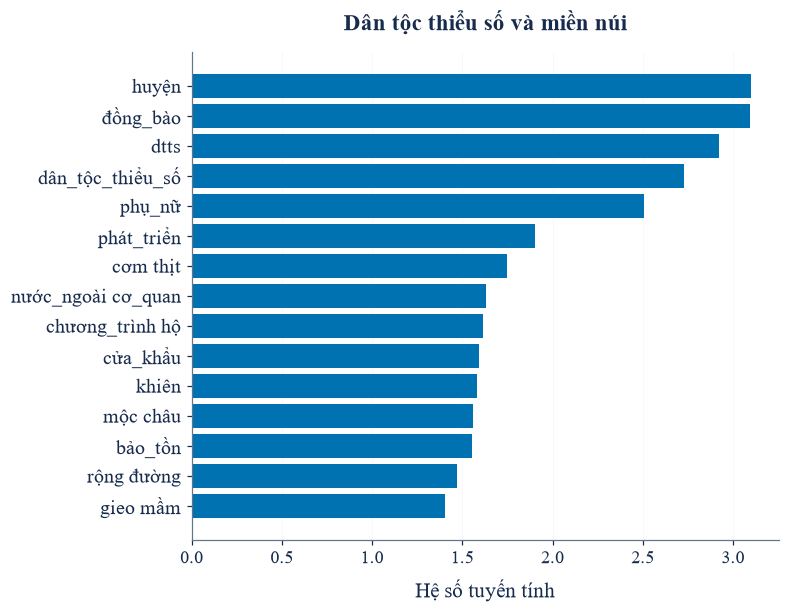

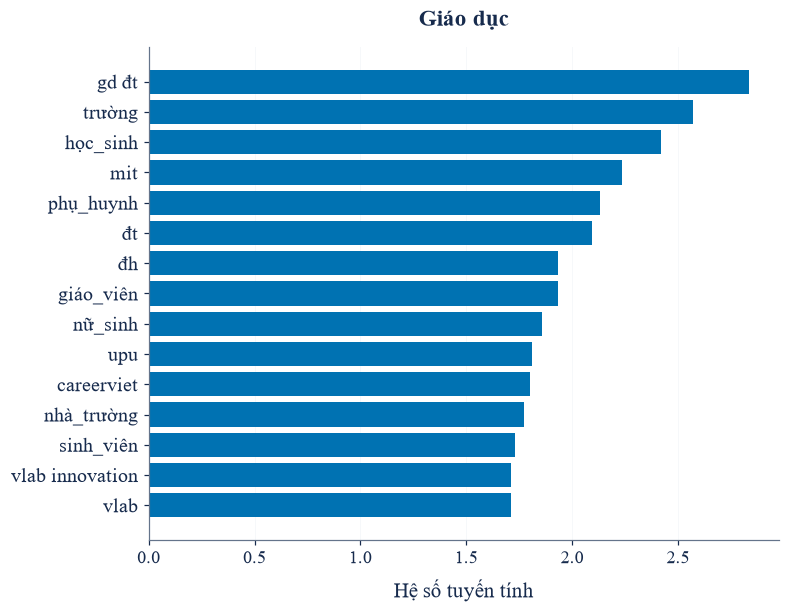

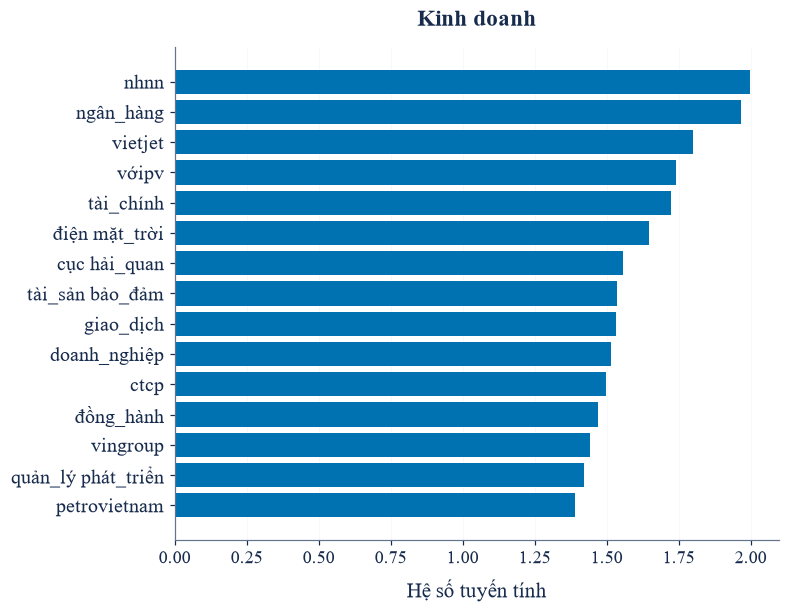

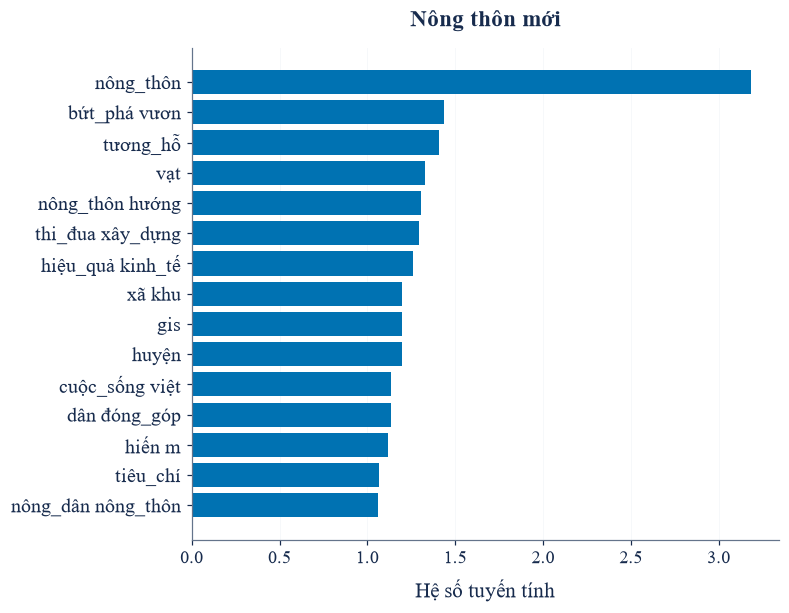

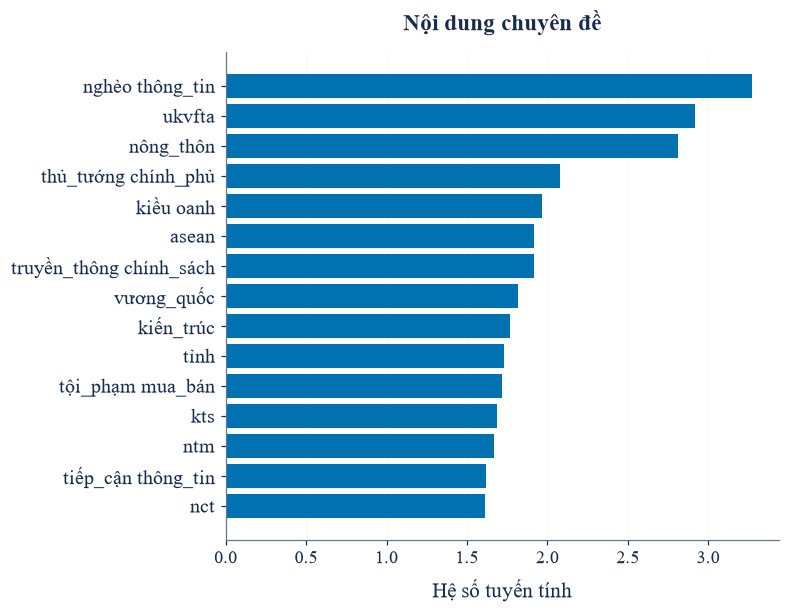

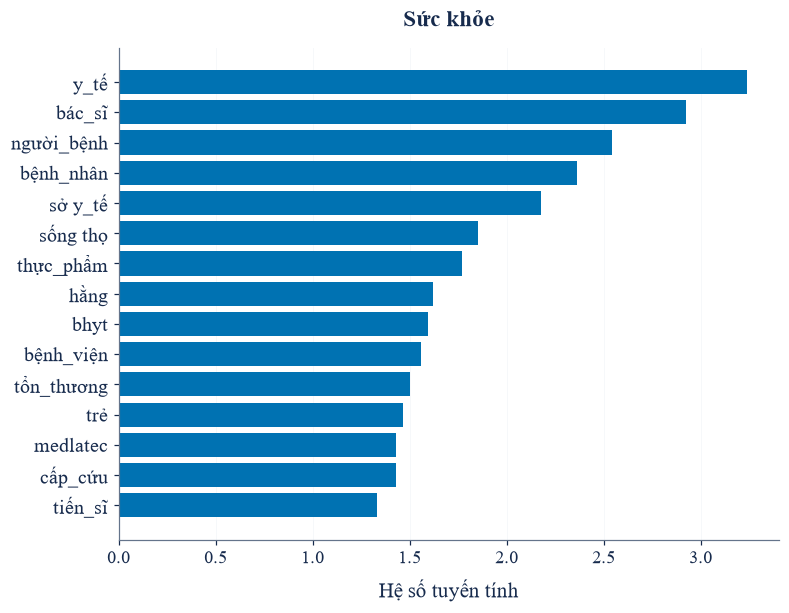

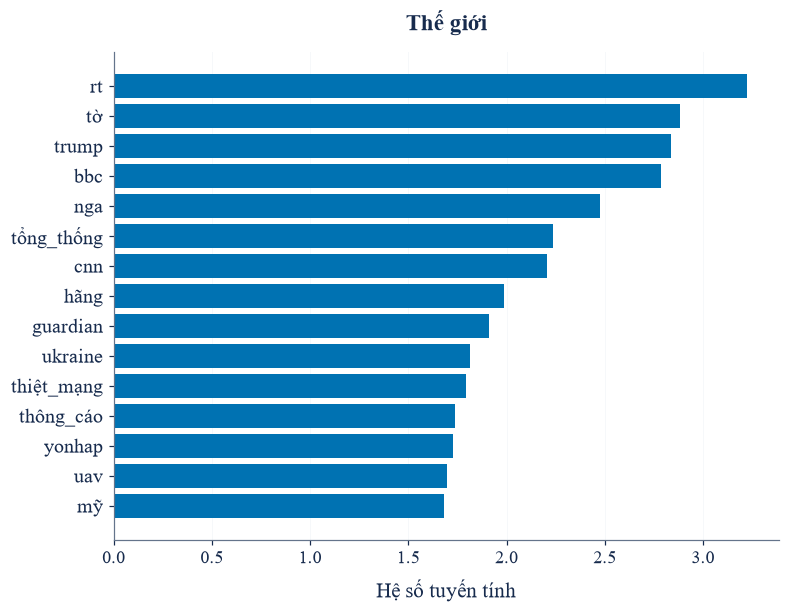

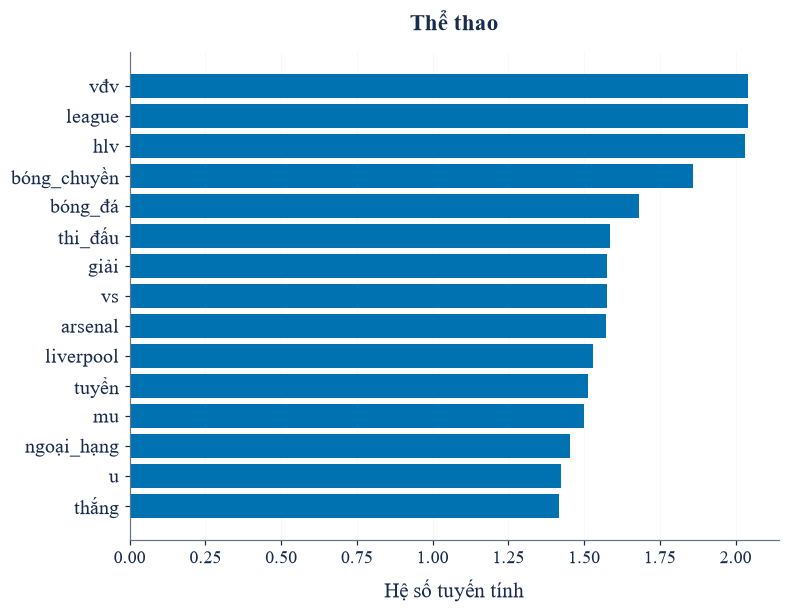

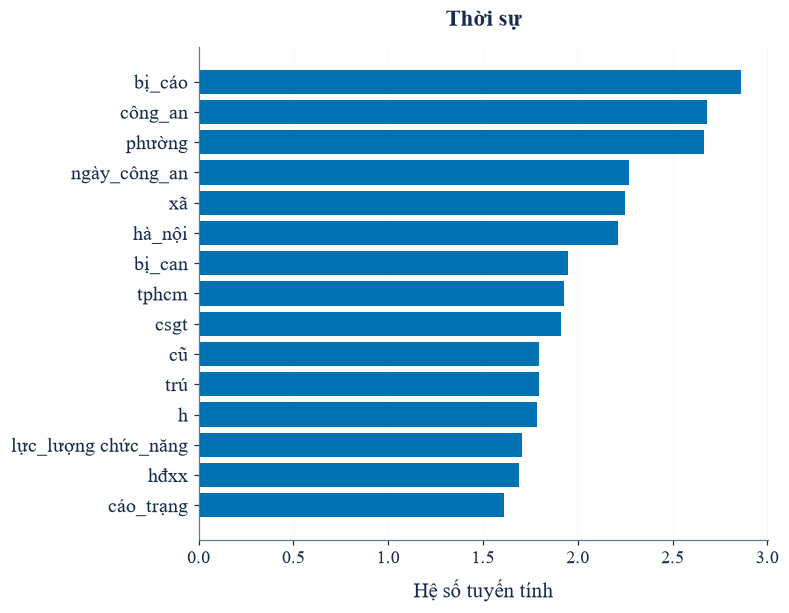

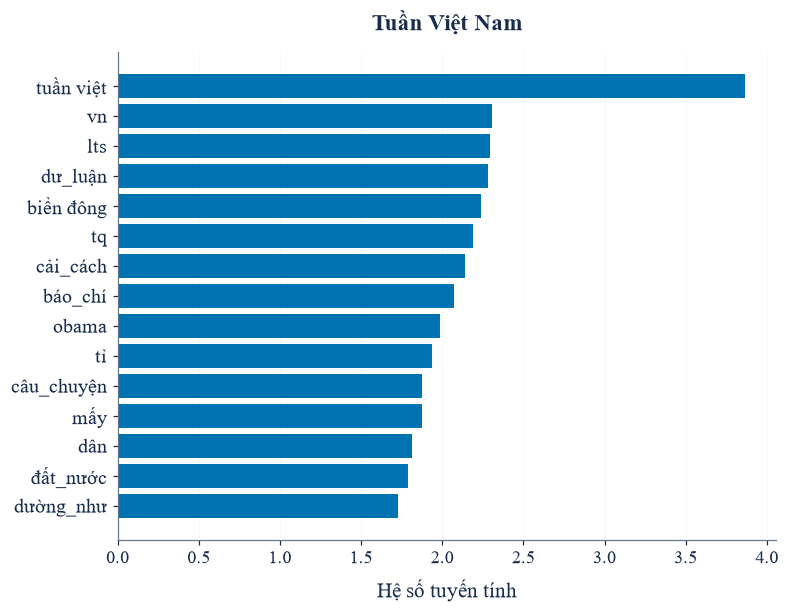

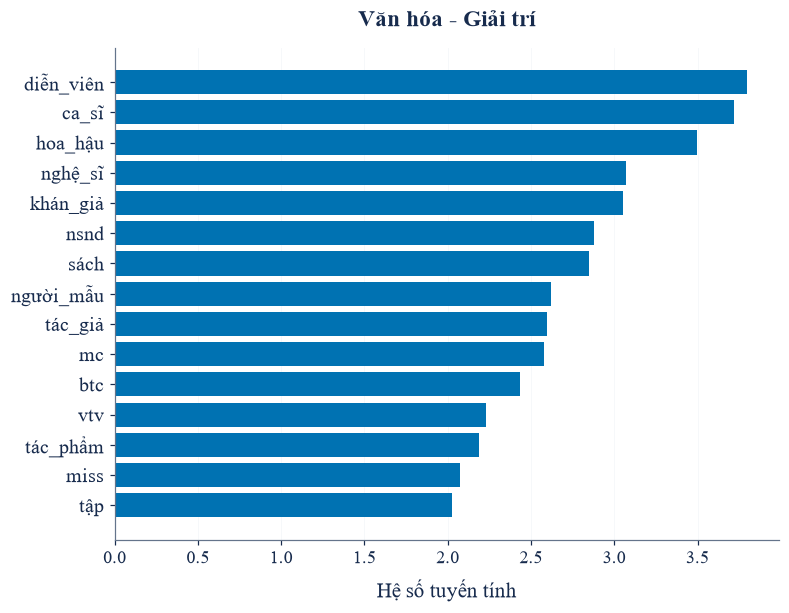

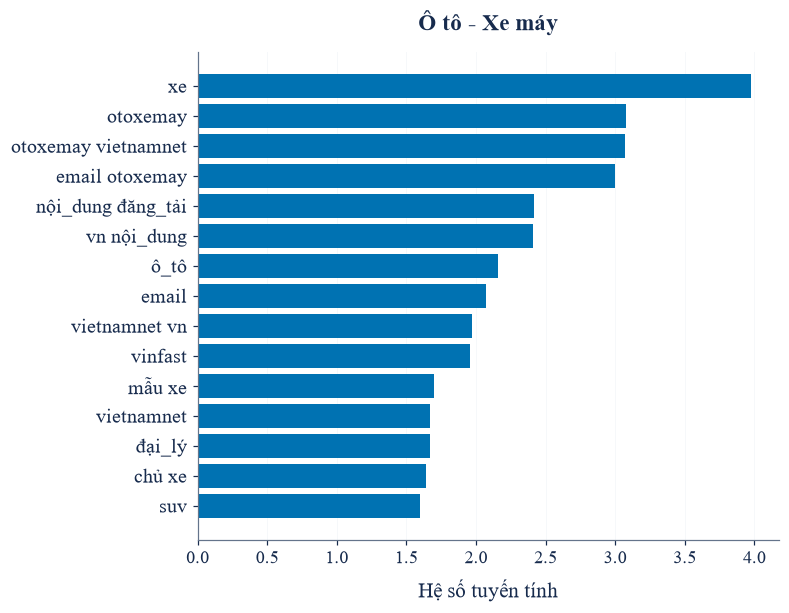

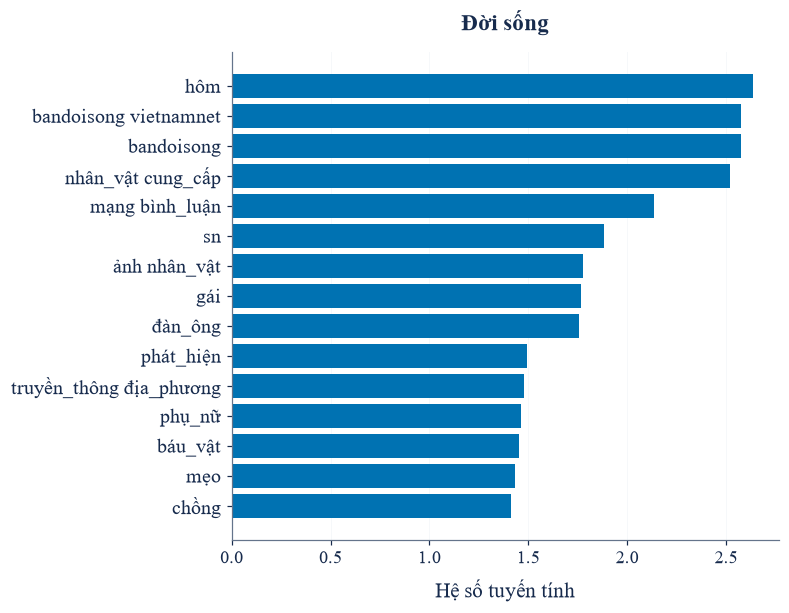

In [29]:
if not search_records and (EVALUATION_DIR / 'search_results.json').is_file():
    search_records = json.loads((EVALUATION_DIR / 'search_results.json').read_text(encoding='utf-8'))
if search_records:
    rows = [row for row in search_records if row['converged']]
    names = [f"{row['candidate']}: {row['config']['name'].replace('_', ' ')} | C={row['config']['C']} | "
             + ('balanced' if row['config']['class_weight'] else 'uniform') for row in rows]
    horizontal_plot(np.array([row['validation']['f1_macro'] for row in rows]), names,
                    'Macro-F1 validation theo cấu hình', 'Macro-F1',
                    'selection/validation_macro_f1', limit=1.12)
    horizontal_plot(np.array([row['fit_seconds'] for row in rows]), names,
                    'Thời gian tối ưu theo cấu hình', 'Giây', 'selection/fit_duration')
feature_names = best_vectorizer.get_feature_names_out()
write_json(EVALUATION_DIR / 'tfidf_summary.json', {
    'n_features': len(feature_names), 'fit_split': 'train',
    'selected_config': selected_config,
    'note': 'Feature weights are model coefficients, not causal explanations.',
})
top_features = []
for i, label in enumerate(classes):
    coefficient = best_estimator.coef_[i]
    indices = np.argsort(coefficient)[-15:][::-1]
    selected_terms = feature_names[indices]
    values = coefficient[indices]
    top_features.append({'id': i, 'label': label,
                         'features': [{'term': term, 'coefficient': float(value)}
                                      for term, value in zip(selected_terms, values)]})
    fig, ax = plt.subplots(figsize=(7.4, 5.8))
    ax.barh(np.arange(len(indices)), values, color=COLORS['primary'])
    ax.set(yticks=np.arange(len(indices)), yticklabels=selected_terms,
           xlabel='Hệ số tuyến tính', title=label)
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.18)
    save_fig(fig, f'features/class_{i:02d}')
write_json(EVALUATION_DIR / 'top_features.json', top_features)


## Xuất kết quả và phân tích trực quan

Kết quả được tính từ dataset, ba tập, quá trình tìm tham số và điểm dự đoán của lượt thực thi.
Mỗi hình hiển thị và xuất riêng. Ma trận sử dụng ID theo bảng nhãn.
Validation chọn pipeline và fit tham số hiệu chỉnh; các bảng chỉ số và phân tích lỗi
bên dưới sử dụng **test độc lập**. Đường Precision–Recall đánh giá từng class theo
cơ chế một-chống-phần-còn-lại; không thay thế quyết định phân loại đa lớp.


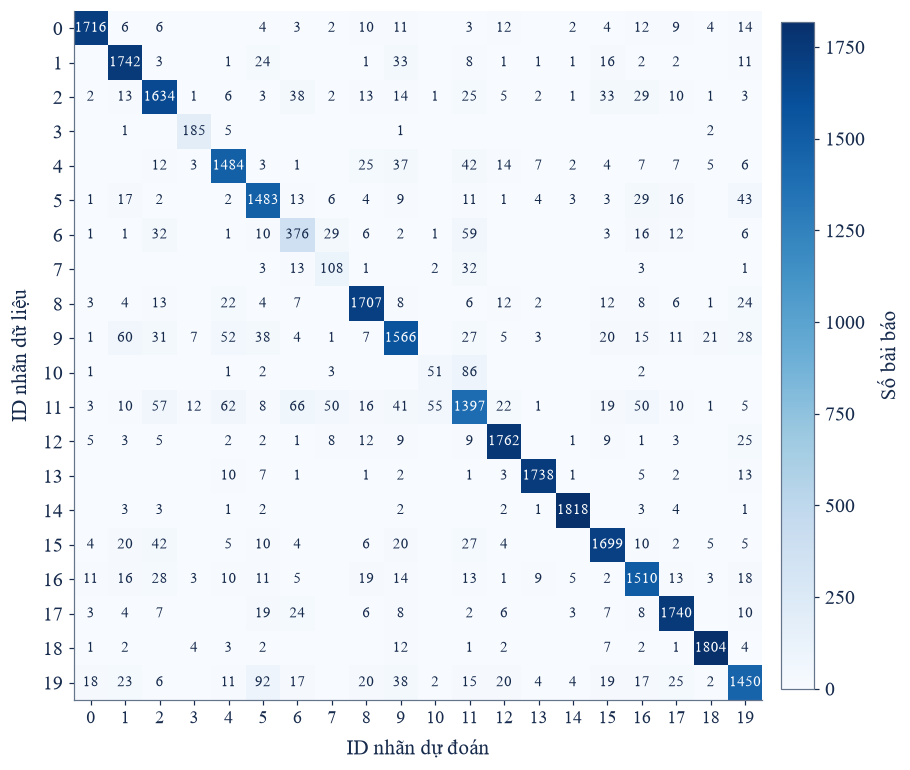

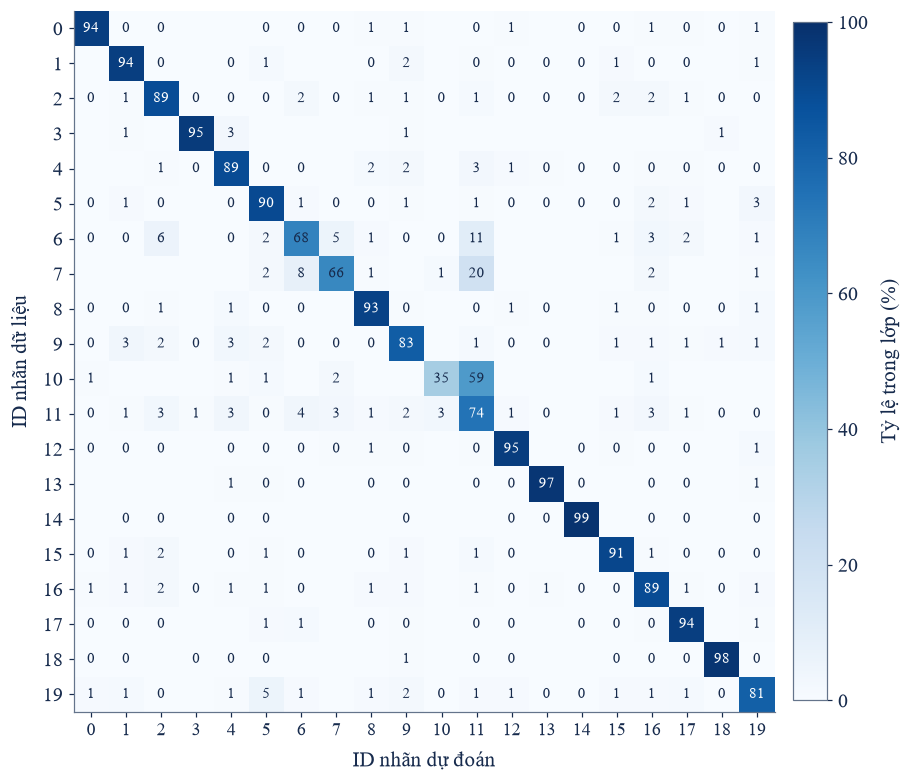

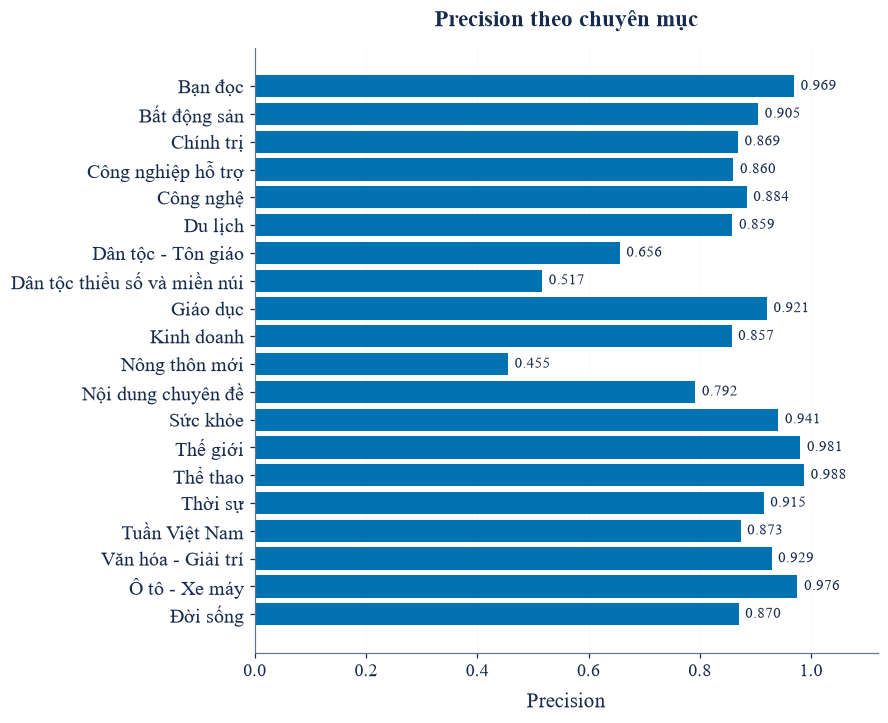

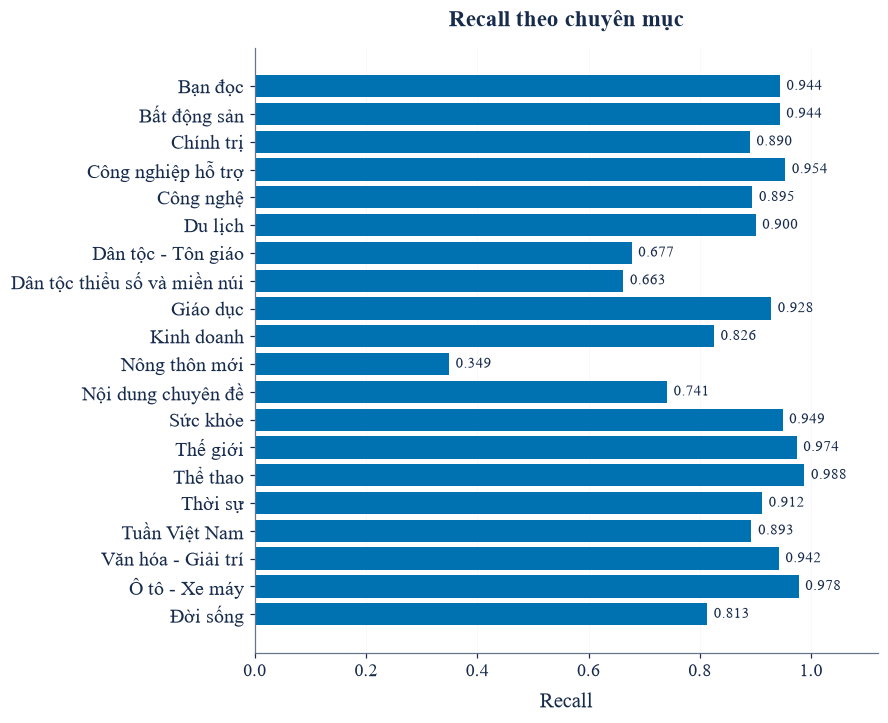

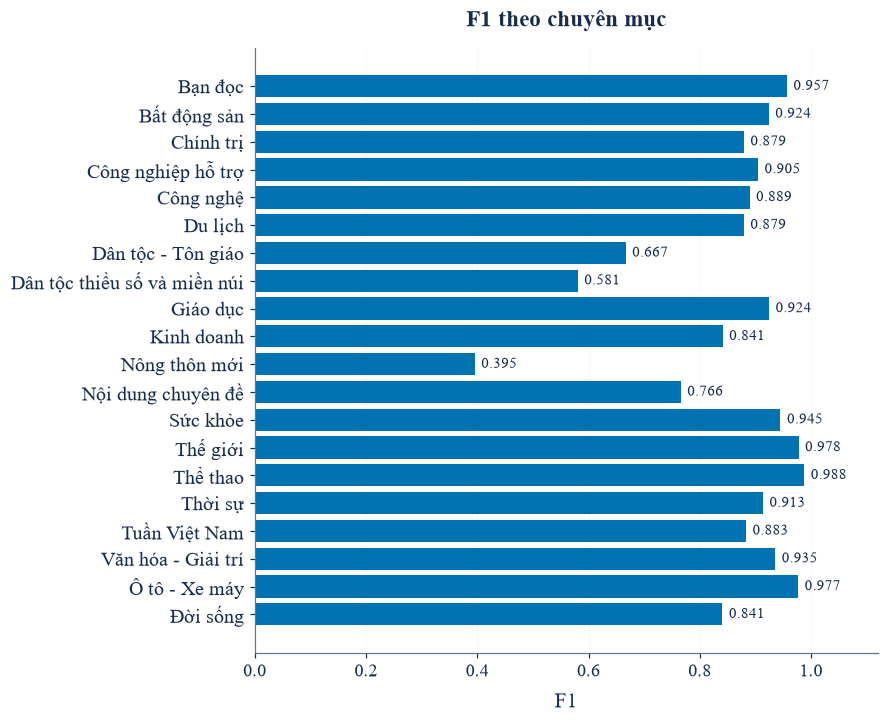

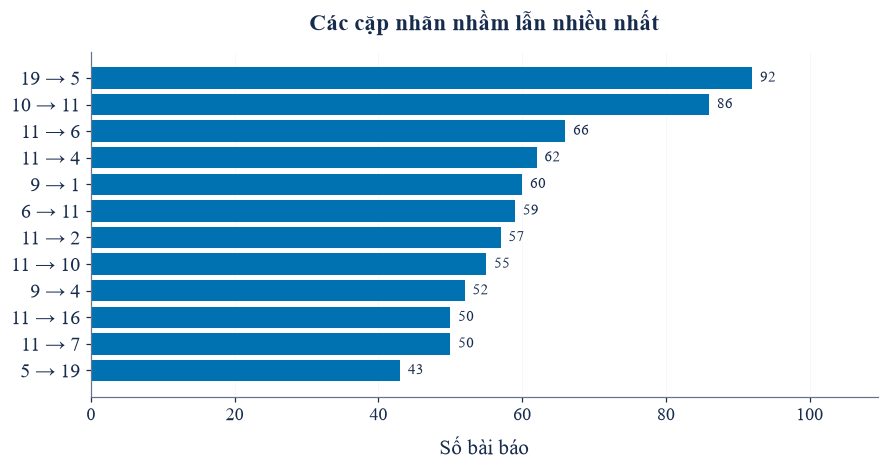

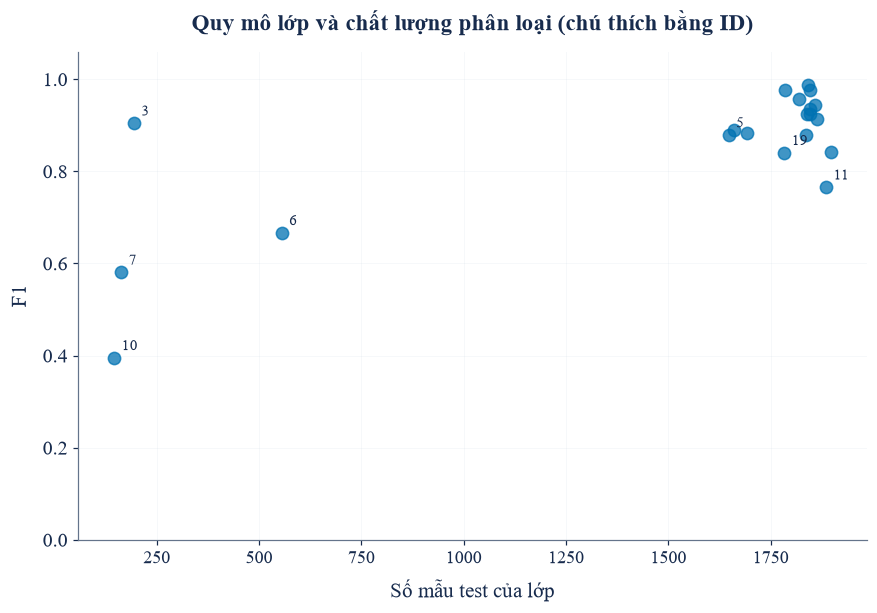

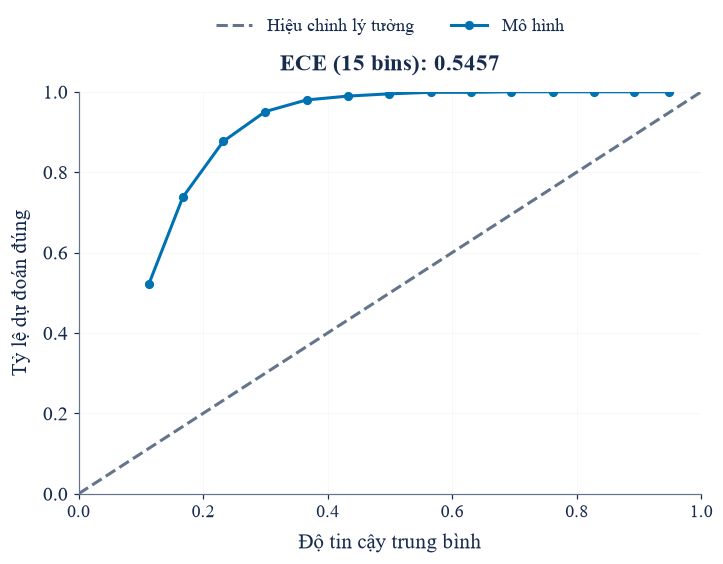

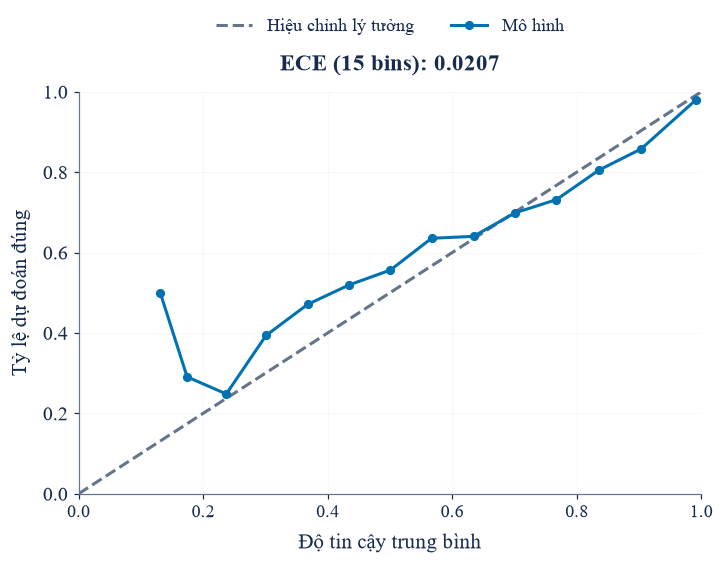

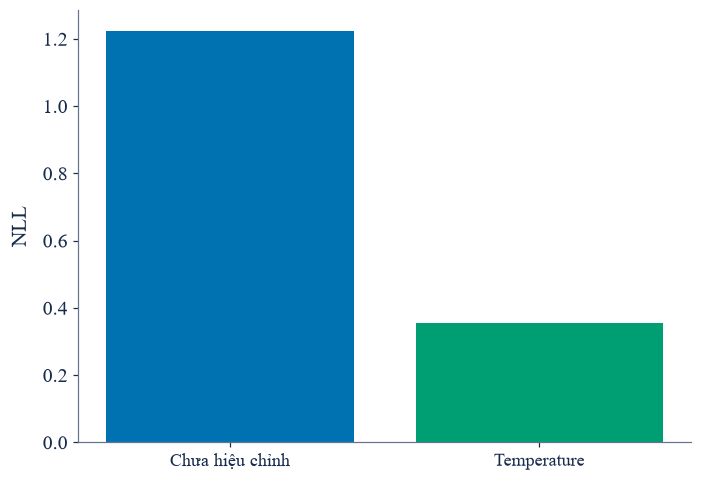

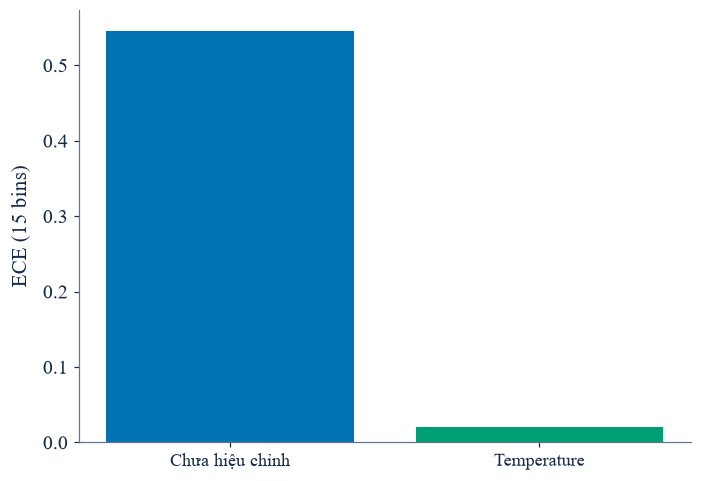

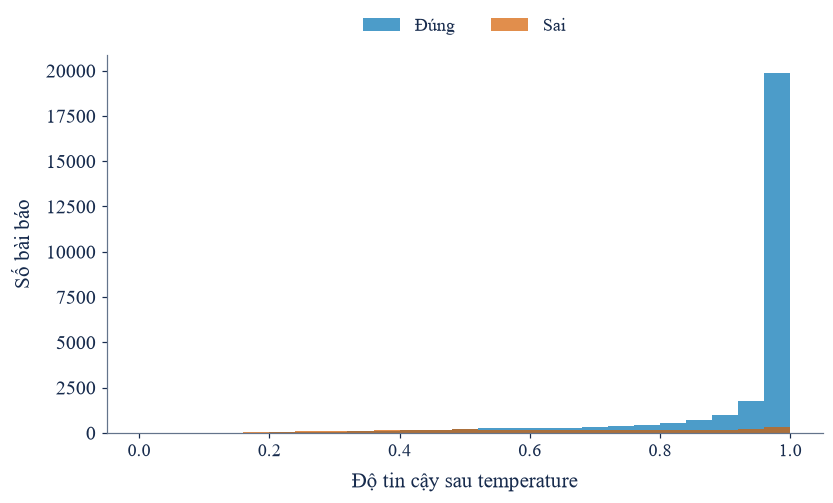

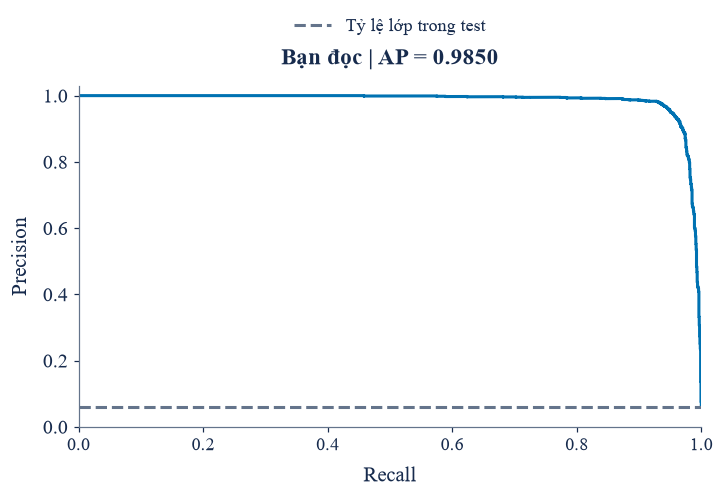

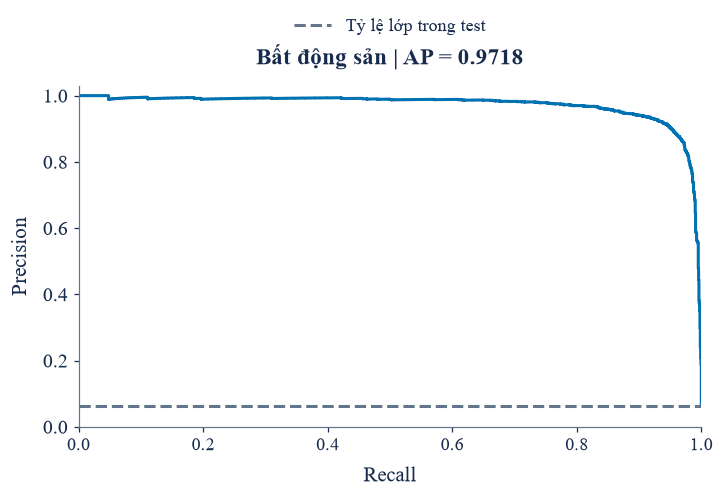

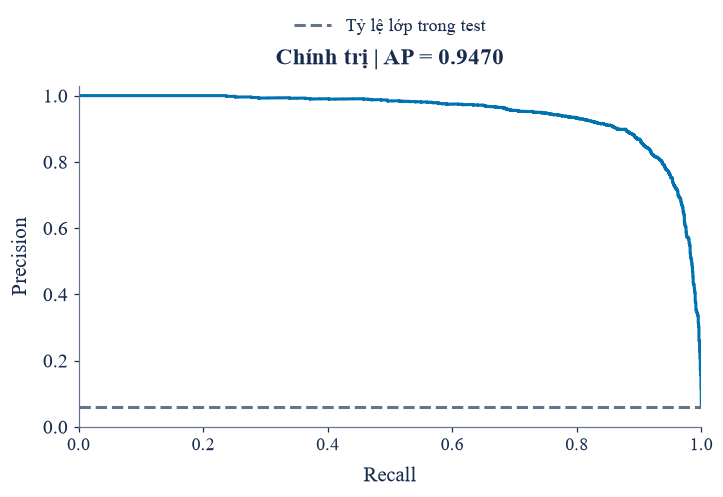

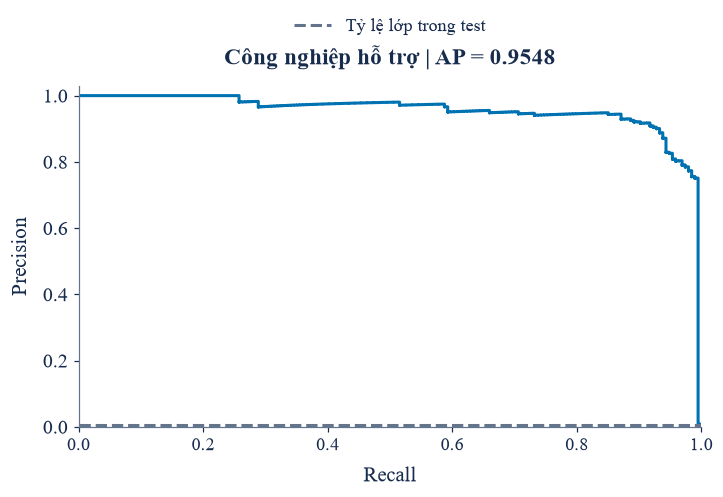

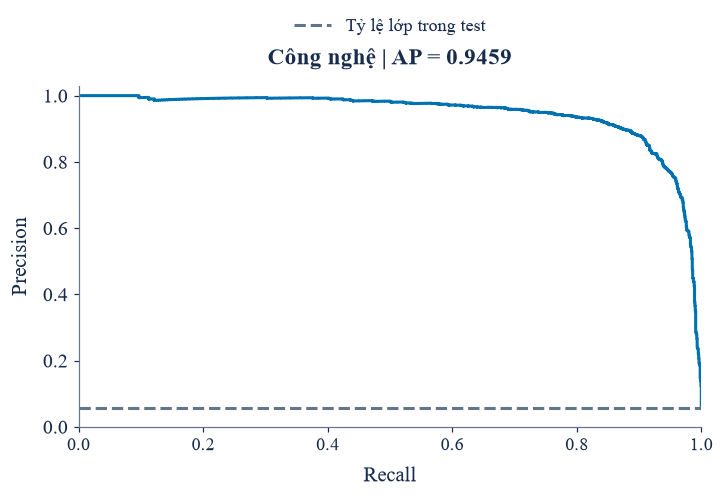

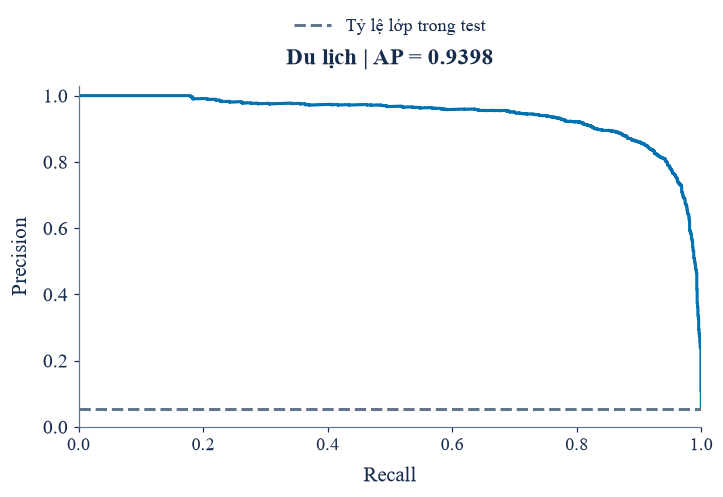

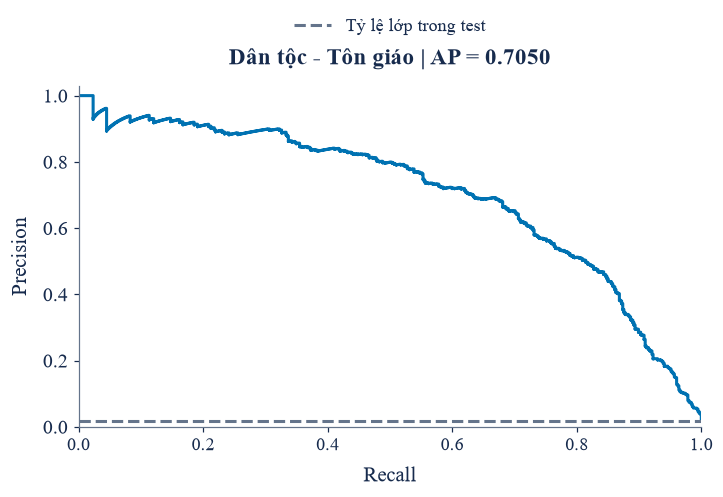

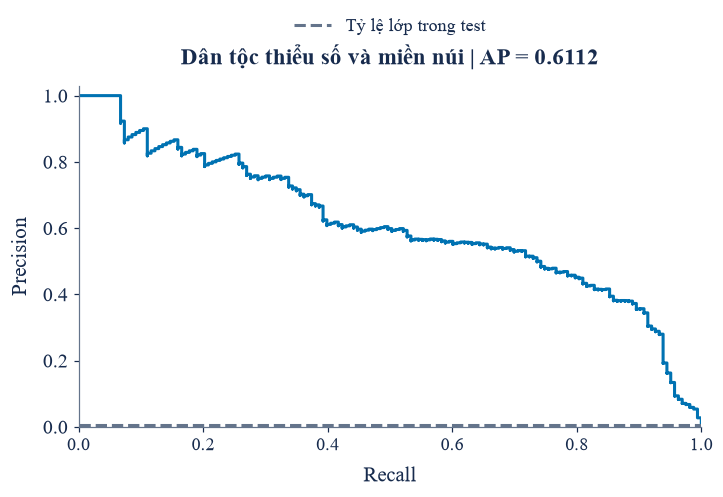

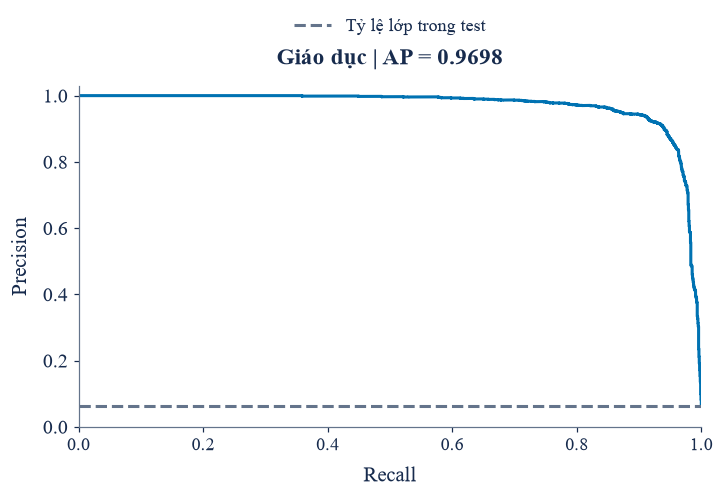

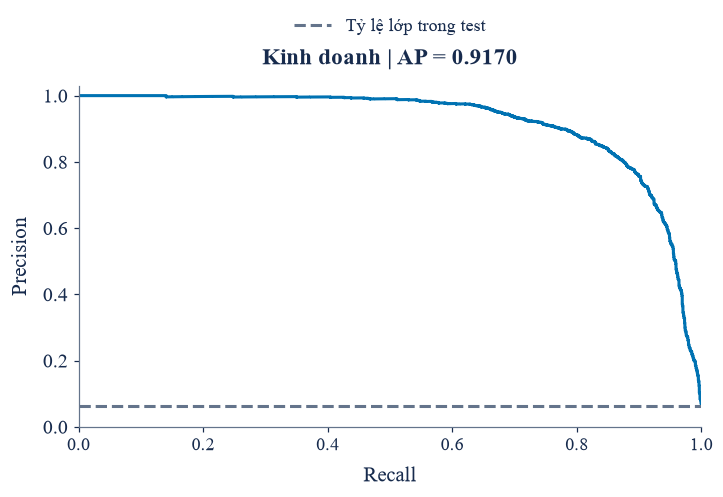

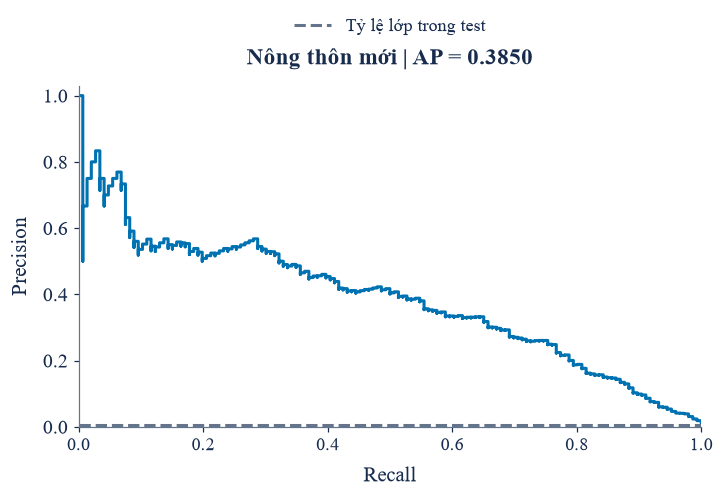

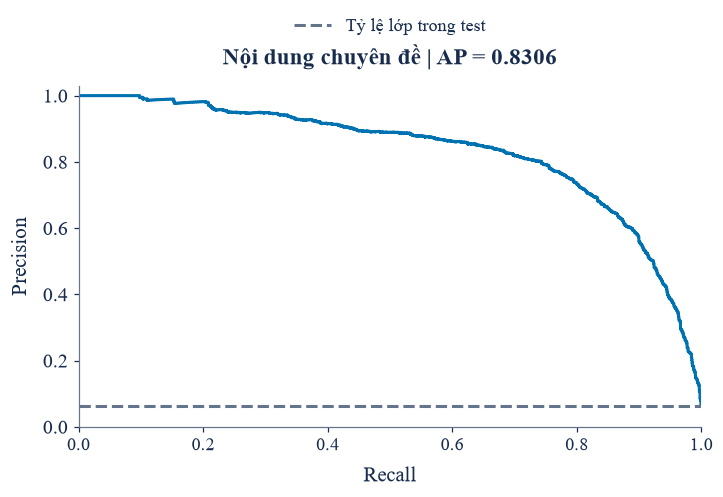

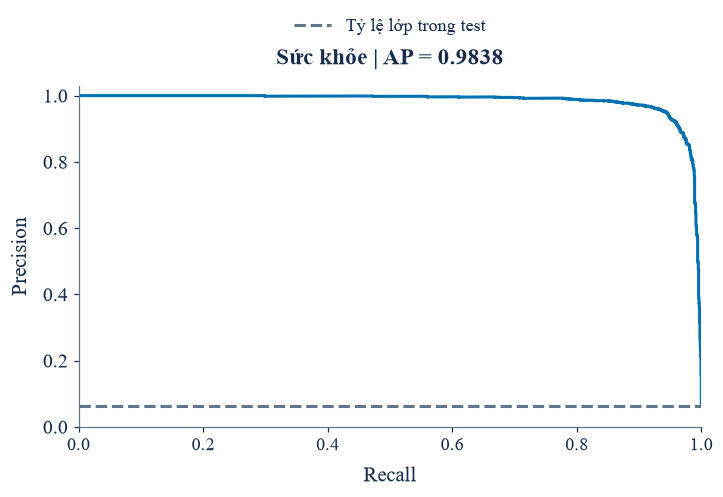

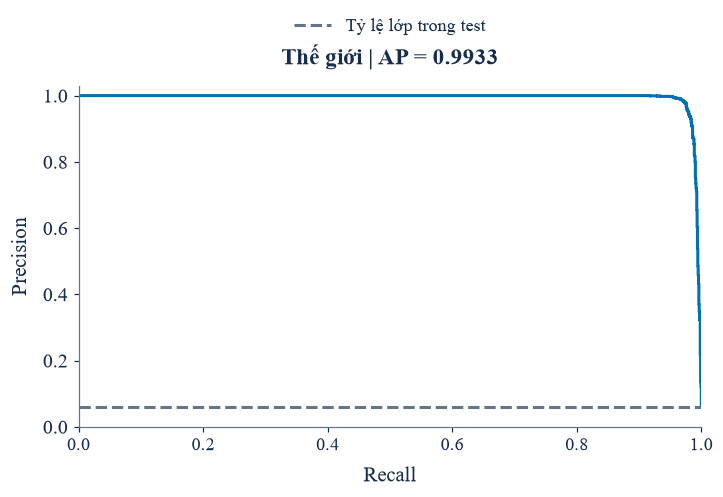

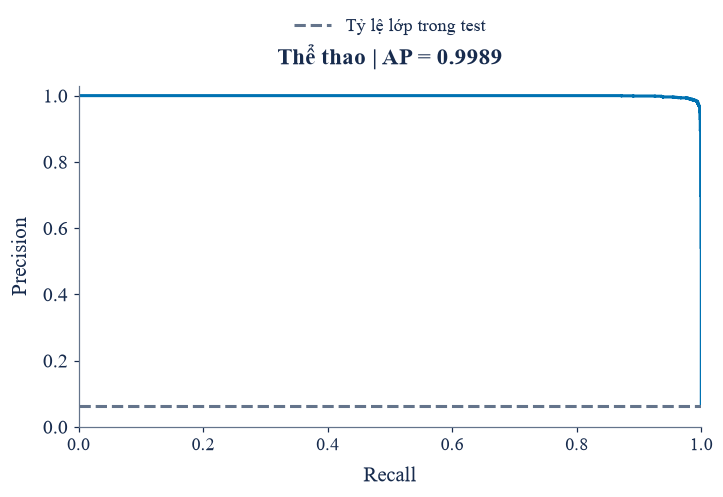

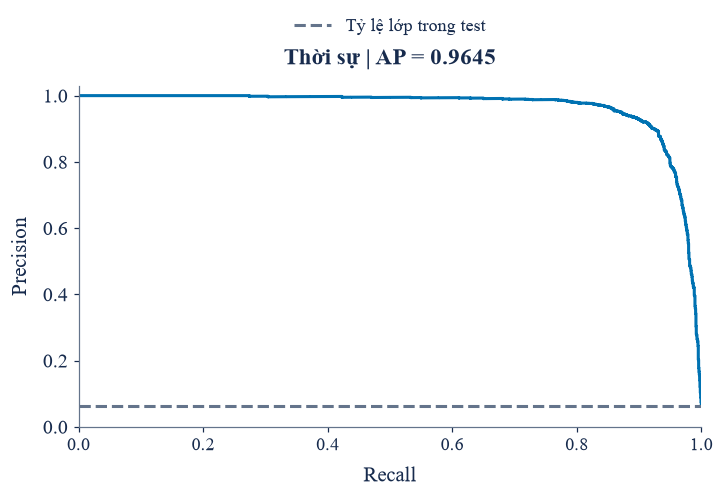

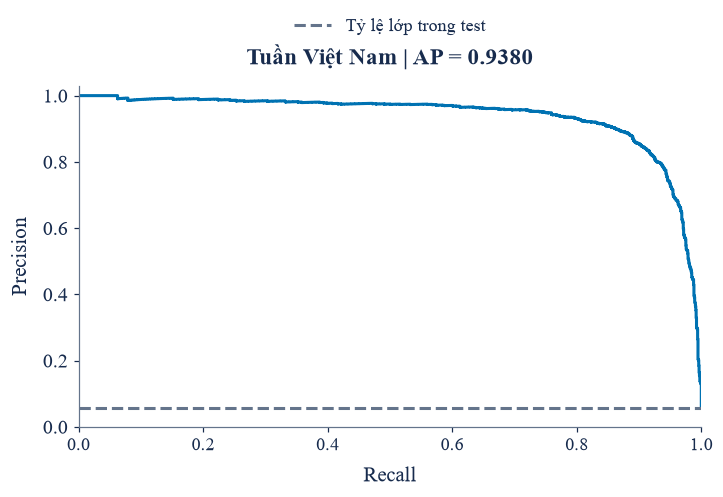

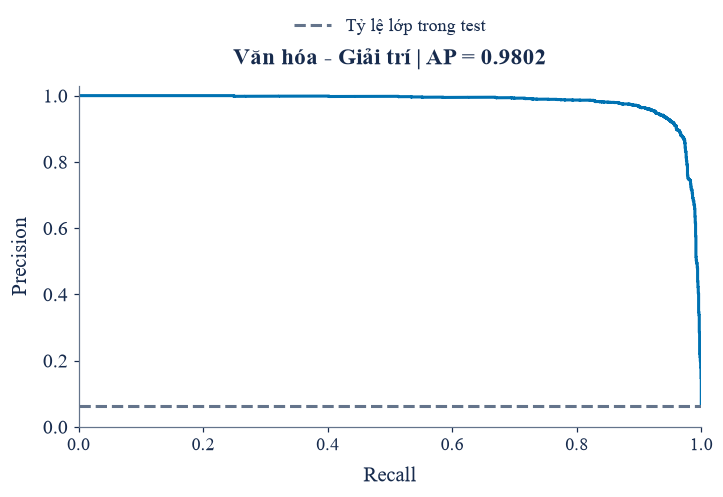

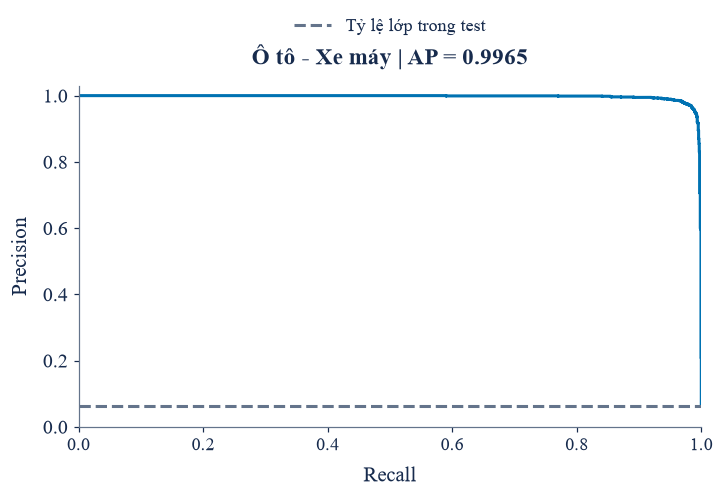

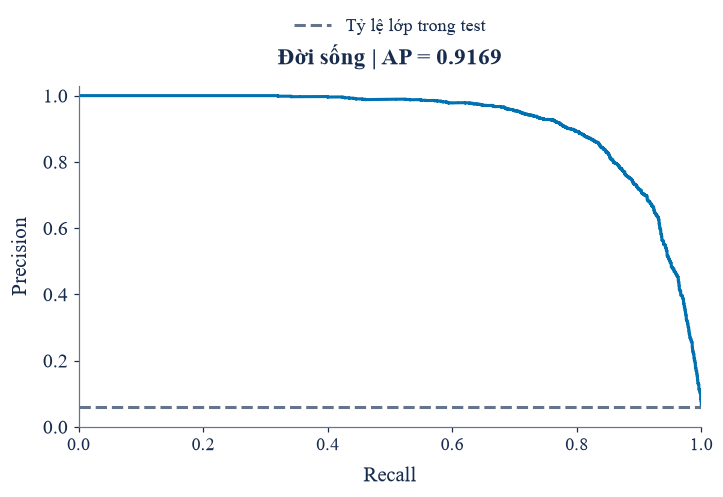

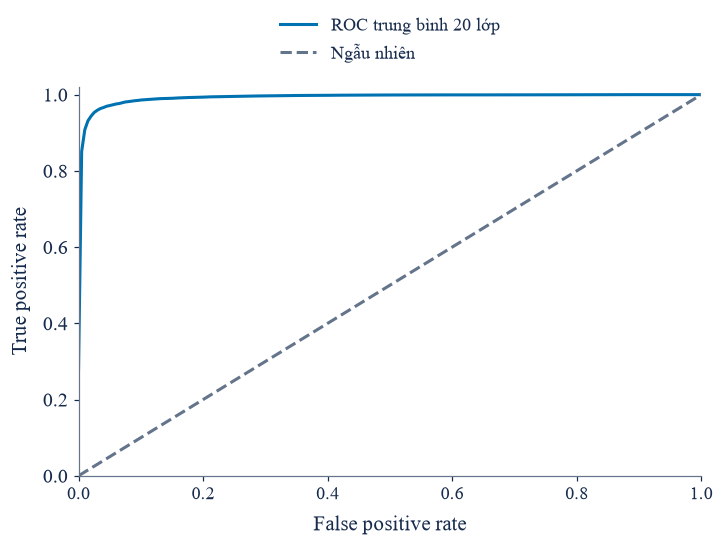

In [30]:
matrix_plot(matrix, 'evaluation/confusion_matrix')
matrix_plot(matrix, 'evaluation/confusion_matrix_normalized', normalized=True)
for metric, title in [('precision', 'Precision'), ('recall', 'Recall'), ('f1-score', 'F1')]:
    horizontal_plot(np.array([report[label][metric] for label in classes]), classes,
                    f'{title} theo chuyên mục', title,
                    'evaluation/per_class_' + metric.replace('-score', ''), limit=1.12)
pairs = sorted([(int(matrix[i, j]), i, j) for i in range(N_CLASSES)
                 for j in range(N_CLASSES) if i != j and matrix[i, j]], reverse=True)[:12]
if pairs:
    horizontal_plot(np.array([item[0] for item in pairs]),
                    [f'{item[1]} → {item[2]}' for item in pairs],
                    'Các cặp nhãn nhầm lẫn nhiều nhất', 'Số bài báo', 'evaluation/top_confusions')
fig, ax = plt.subplots(figsize=(8.2, 5.8))
support = np.array([report[label]['support'] for label in classes])
f1_values = np.array([report[label]['f1-score'] for label in classes])
ax.scatter(support, f1_values, color=COLORS['primary'], alpha=0.75, s=65)
for i in range(N_CLASSES):
    if support[i] < np.quantile(support, 0.25) or f1_values[i] < np.quantile(f1_values, 0.25):
        ax.annotate(str(i), (support[i], f1_values[i]), xytext=(5, 5),
                    textcoords='offset points', fontsize=10)
ax.set(xlabel='Số mẫu test của lớp', ylabel='F1', ylim=(0, 1.06),
       title='Quy mô lớp và chất lượng phân loại (chú thích bằng ID)')
ax.grid(alpha=0.18)
save_fig(fig, 'evaluation/support_vs_f1')
for name, diagnostic in [('before', before), ('temperature', after)]:
    fig, ax = plt.subplots(figsize=(6.8, 5.4))
    rows = diagnostic['bins']
    ax.plot([0, 1], [0, 1], '--', color=COLORS['muted'], label='Hiệu chỉnh lý tưởng')
    ax.plot([row['confidence'] for row in rows], [row['accuracy'] for row in rows],
            'o-', color=COLORS['primary'], label='Mô hình')
    ax.set(xlabel='Độ tin cậy trung bình', ylabel='Tỷ lệ dự đoán đúng',
           xlim=(0, 1), ylim=(0, 1), title=f'ECE (15 bins): {diagnostic["ece_15_bins"]:.4f}')
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.10), ncol=2, frameon=False)
    ax.grid(alpha=0.18)
    save_fig(fig, 'evaluation/reliability_' + name)
for name, values in [('nll', [before['nll'], after['nll']]),
                      ('ece', [before['ece_15_bins'], after['ece_15_bins']])]:
    fig, ax = plt.subplots(figsize=(6.6, 4.6))
    ax.bar(['Chưa hiệu chỉnh', 'Temperature'], values,
            color=[COLORS['primary'], COLORS['secondary']])
    ax.set(ylabel='NLL' if name == 'nll' else 'ECE (15 bins)')
    save_fig(fig, 'evaluation/' + name + '_comparison')
fig, ax = plt.subplots(figsize=(7.8, 4.8))
confidence = test_probabilities.max(axis=1)
correct = y_test == test_predictions
for mask, title, color in [(correct, 'Đúng', 'primary'), (~correct, 'Sai', 'warning')]:
    ax.hist(confidence[mask], bins=np.linspace(0, 1, 26), alpha=0.7,
             label=title, color=COLORS[color])
ax.set(xlabel='Độ tin cậy sau temperature', ylabel='Số bài báo')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False)
save_fig(fig, 'evaluation/confidence')
curves = []
common_fpr = np.linspace(0, 1, 200)
for i, label in enumerate(classes):
    binary = (y_test == i).astype(int)
    precision, recall, _ = precision_recall_curve(binary, test_probabilities[:, i])
    ap = float(average_precision_score(binary, test_probabilities[:, i]))
    fpr, tpr, _ = roc_curve(binary, test_probabilities[:, i])
    curves.append({'id': i, 'label': label, 'average_precision': ap,
                   'roc_auc': float(auc(fpr, tpr)),
                   'interpolated_tpr': np.interp(common_fpr, fpr, tpr).tolist()})
    fig, ax = plt.subplots(figsize=(6.8, 4.8))
    ax.step(recall, precision, where='post', color=COLORS['primary'])
    ax.axhline(binary.mean(), ls='--', color=COLORS['muted'], label='Tỷ lệ lớp trong test')
    ax.set(xlabel='Recall', ylabel='Precision', xlim=(0, 1), ylim=(0, 1.03),
           title=f'{label} | AP = {ap:.4f}')
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.10), frameon=False)
    save_fig(fig, f'evaluation/precision_recall/class_{i:02d}')
write_json(EVALUATION_DIR / 'ranking_metrics.json', [
    {key: value for key, value in row.items() if key != 'interpolated_tpr'} for row in curves])
fig, ax = plt.subplots(figsize=(6.8, 5.2))
ax.plot(common_fpr, np.mean([row['interpolated_tpr'] for row in curves], axis=0),
        color=COLORS['primary'], label='ROC trung bình 20 lớp')
ax.plot([0, 1], [0, 1], '--', color=COLORS['muted'], label='Ngẫu nhiên')
ax.set(xlabel='False positive rate', ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), frameon=False)
save_fig(fig, 'evaluation/macro_roc')


In [31]:
image_paths = sorted(FIGURE_DIR.rglob('*.png'))
write_json(RESULT_DIR / 'figure_manifest.json', {
    'model': MODEL_KEY, 'format': 'PNG', 'dpi': 300,
    'files': [{'path': path.relative_to(RESULT_DIR).as_posix(),
               'sha256': file_sha256(path)} for path in image_paths],
})
write_json(MODEL_DIR / 'artifact_manifest.json', {
    'model': MODEL_KEY, 'corpus_signature': corpus_signature,
    'split_signature': split_signature,
    'files': [{'name': path.name, 'sha256': file_sha256(path)}
              for path in sorted(MODEL_DIR.iterdir())
              if path.is_file() and path.name != 'artifact_manifest.json'],
})
log(f'Hoàn tất: {len(image_paths)} PNG độc lập; model tại {MODEL_DIR}; kết quả tại {RESULT_DIR}.')
log('Bảng đối chiếu: comparison summary; chỉ chứa cấu hình được chọn bằng validation.')
display(pd.DataFrame([{
    'Mô hình': MODEL_NAME, 'Accuracy': test_metrics['accuracy'],
    'Macro-F1': test_metrics['f1_macro'], 'Weighted-F1': test_metrics['f1_weighted'],
    'NLL sau hiệu chỉnh': after['nll'], 'ECE sau hiệu chỉnh': after['ece_15_bins'],
    'Số mẫu test': len(y_test),
}]))


# Hoàn tất: 63 PNG độc lập; model tại C:\Users\DELL\Downloads\CTCHDTXLNNTN\BTL_NLP_VietnamNet\model\svm; kết quả tại C:\Users\DELL\Downloads\CTCHDTXLNNTN\BTL_NLP_VietnamNet\result\svm.
# Bảng đối chiếu: comparison summary; chỉ chứa cấu hình được chọn bằng validation.


,Mô hình,Accuracy,Macro-F1,Weighted-F1,NLL sau hiệu chỉnh,ECE sau hiệu chỉnh,Số mẫu test
0,Linear SVM,0.89915,0.853308,0.898771,0.354016,0.020738,29995


## Sử dụng kết quả trong báo cáo

`result/svm/evaluation/comparison_summary.json` chứa cấu hình được chọn,
fingerprint corpus, split, hash danh sách URL test và số liệu test. Các file
`search_results.json` chỉ có validation; không lấy số tốt nhất trên test qua
nhiều cấu hình. Báo cáo cần trình bày C, trọng số lớp, profile TF-IDF, seed,
thời gian tìm tham số và thời gian fit cấu hình được chọn.

Accuracy/F1 trước và sau temperature giống nhau. Xác suất là ánh xạ từ margin; không gọi margin là xác suất.
Thời gian inference bao gồm tạo TF-IDF
và tính score, không gồm phân đoạn tiếng Việt. Kết quả một seed cùng một nguồn
dữ liệu chưa phản ánh độ biến thiên ngoài miền. Lập luận giải thích từ trọng số
từ vựng là mô tả mô hình, không phải quan hệ nhân quả.

Tài liệu: [TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html),
[LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html).
